# Prediksi Harga Beras, Cabai Rawit, dan Bawang Merah di Provinsi DI Yogyakarta

Prediksi harga harian H+1, H+7, dan H+30 dengan alur: imputasi → transformasi `log1p` → _differencing_ orde 1 → LightGBM (`ForecasterDirect`) dengan hyperparameter hasil Genetic Algorithm.


## Import Library


In [1]:
import warnings
from pathlib import Path

import joblib as jl
import lightgbm as lgb
import matplotlib.pyplot as plt
import missingno as mgno
import numpy as np
import pandas as pd
import pygad
import seaborn as sns
import xgboost as xgb
from skforecast.direct import ForecasterDirect
from skforecast.exceptions import IgnoredArgumentWarning, LongTrainingWarning
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
from skforecast.preprocessing import CalendarFeatures, RollingFeatures
from skforecast.utils import save_forecaster
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,
    r2_score,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from statsmodels.tsa.stattools import adfuller

/home/yosiacokr/Documents/Project/pangan-forecasting/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
warnings.simplefilter("ignore", category=IgnoredArgumentWarning)
warnings.simplefilter("ignore", category=LongTrainingWarning)

## Memuat Dataset (CSV)


In [3]:
df_raw = pd.read_csv("DATASET-BERAS.csv")
df_raw.head()

,tanggal,Beras Kualitas Bawah I,Beras Kualitas Bawah II,Beras Kualitas Medium I,Beras Kualitas Medium II,Beras Kualitas Super I,Beras Kualitas Super II,Bawang Merah Ukuran Sedang,Cabai Rawit Hijau,Cabai Rawit Merah
0,2021-01-04,10.4,9.9,11.75,11.0,12.75,12.4,32.25,56.25,62.50
1,2021-01-05,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.25,68.75
2,2021-01-06,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.25,68.75
3,2021-01-07,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.00,71.25
4,2021-01-08,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.00,71.25


## Menetapkan Indeks Tanggal dan Split Train/Test


In [4]:
df_raw.index = pd.DatetimeIndex(df_raw["tanggal"], yearfirst=True)
df_raw.drop(columns=["tanggal"], inplace=True)
df_raw = df_raw.asfreq("D")

In [5]:
holdout = TimeSeriesSplit(
    n_splits=5,
)

train_idx, test_idx = list(holdout.split(df_raw))[-1]
raw_train = df_raw.iloc[train_idx].copy()
raw_test = df_raw.iloc[test_idx].copy()

train_filled_interpolation = raw_train.interpolate(
    method="time", limit_direction="both"
)
test_filled_interpolation = (
    pd.concat([train_filled_interpolation.tail(1), raw_test]).ffill().iloc[1:]
)
df_cleaned = pd.concat([train_filled_interpolation, test_filled_interpolation]).loc[
    raw_train.index[0] :
]

assert df_cleaned.index.equals(df_raw.loc[raw_train.index[0] :].index)
assert not df_cleaned.isna().any().any()
print("Train:", raw_train.index.min().date(), "->", raw_train.index.max().date())
print("Test:", raw_test.index.min().date(), "->", raw_test.index.max().date())

Train: 2021-01-04 -> 2025-08-29
Test: 2025-08-30 -> 2026-08-03


## Exploratory Data Analysis (EDA)


## Memeriksa Informasi dan Tipe Data


In [6]:
df_raw.info()
df_raw.dtypes

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2038 entries, 2021-01-04 to 2026-08-03
Freq: D
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Beras Kualitas Bawah I      1427 non-null   float64
 1   Beras Kualitas Bawah II     1427 non-null   float64
 2   Beras Kualitas Medium I     1427 non-null   float64
 3   Beras Kualitas Medium II    1427 non-null   float64
 4   Beras Kualitas Super I      1427 non-null   float64
 5   Beras Kualitas Super II     1427 non-null   float64
 6   Bawang Merah Ukuran Sedang  1427 non-null   float64
 7   Cabai Rawit Hijau           1427 non-null   float64
 8   Cabai Rawit Merah           1427 non-null   float64
dtypes: float64(9)
memory usage: 223.8 KB


Beras Kualitas Bawah I        float64
Beras Kualitas Bawah II       float64
Beras Kualitas Medium I       float64
Beras Kualitas Medium II      float64
Beras Kualitas Super I        float64
Beras Kualitas Super II       float64
Bawang Merah Ukuran Sedang    float64
Cabai Rawit Hijau             float64
Cabai Rawit Merah             float64
dtype: object

## Persentase Missing Value


In [7]:
percentages = (df_raw.isnull().sum() / len(df_raw)) * 100
print(percentages)

Beras Kualitas Bawah I        29.980373
Beras Kualitas Bawah II       29.980373
Beras Kualitas Medium I       29.980373
Beras Kualitas Medium II      29.980373
Beras Kualitas Super I        29.980373
Beras Kualitas Super II       29.980373
Bawang Merah Ukuran Sedang    29.980373
Cabai Rawit Hijau             29.980373
Cabai Rawit Merah             29.980373
dtype: float64


## Visualisasi Distribusi dan Outlier


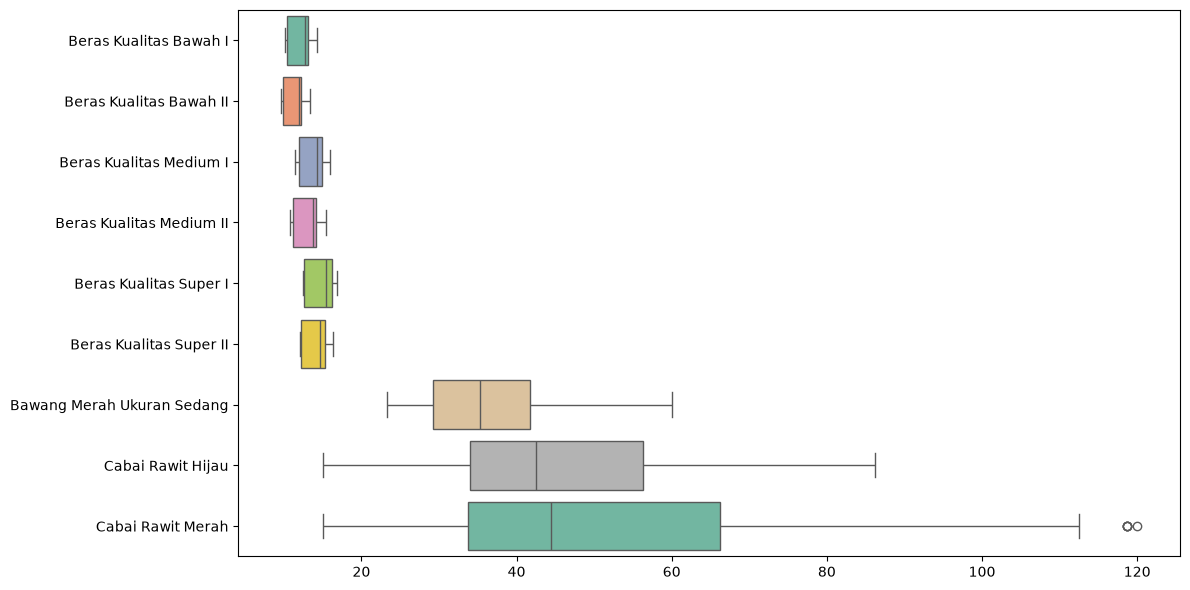

In [8]:
nums_cols = df_raw.select_dtypes(include="number").columns

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_raw[nums_cols], orient="h", palette="Set2", showfliers=True, whis=1.5
)
plt.tight_layout()
plt.show()

## Matriks Korelasi


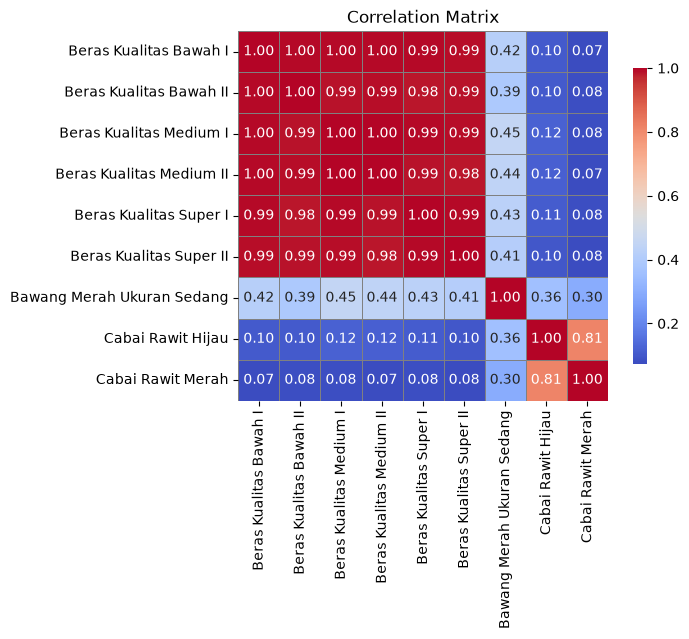

In [9]:
matrix_corr = df_raw[nums_cols].corr()
sns.heatmap(
    matrix_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    cbar_kws={"shrink": 0.8},
    linewidths=0.5,
    linecolor="gray",
)
plt.title("Correlation Matrix")
plt.show()

## Visualisasi Missing Value pada Data Asli


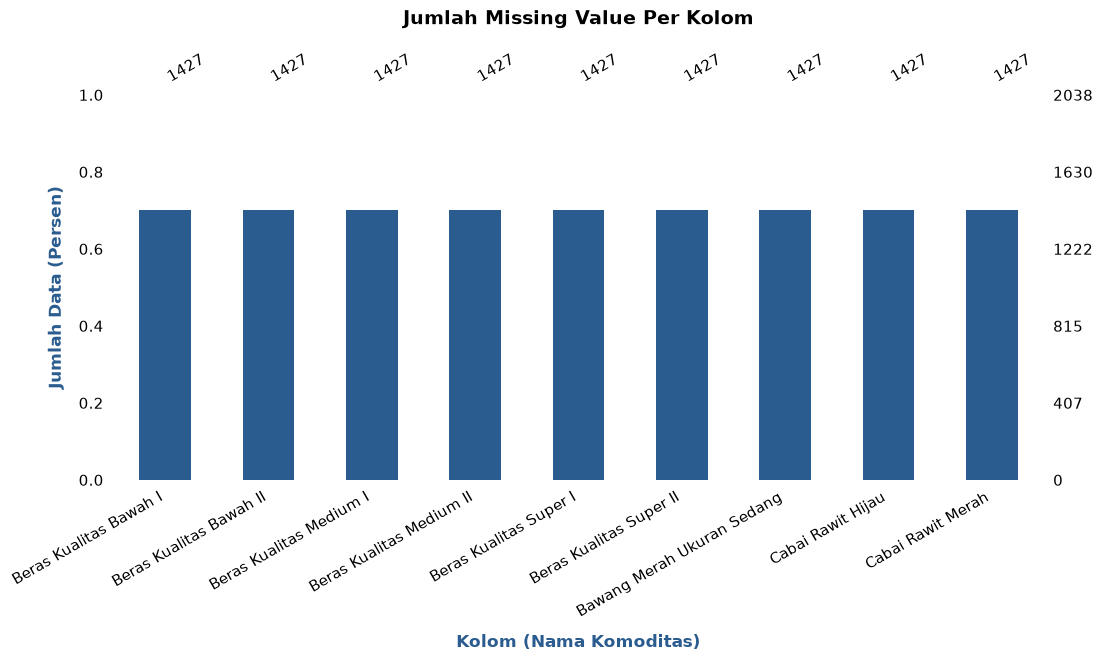

In [10]:
def plot_missing_bar(df, title):
    ax = mgno.bar(
        df,
        figsize=(12, 5),
        fontsize=11,
        labels=True,
        sort="ascending",
        p=True,
        color="#2b5c8f",
        label_rotation=30,
    )
    label_style = {
        "fontsize": 12,
        "labelpad": 10,
        "fontweight": "bold",
        "color": "#2b5c8f",
    }
    ax.set_title(title, fontsize=14, fontweight="bold", pad=20)
    ax.set_xlabel("Kolom (Nama Komoditas)", **label_style)
    ax.set_ylabel("Jumlah Data (Persen)", **label_style)


plot_missing_bar(df_raw, "Jumlah Missing Value Per Kolom")

## Visualisasi Missing Value Setelah Imputasi


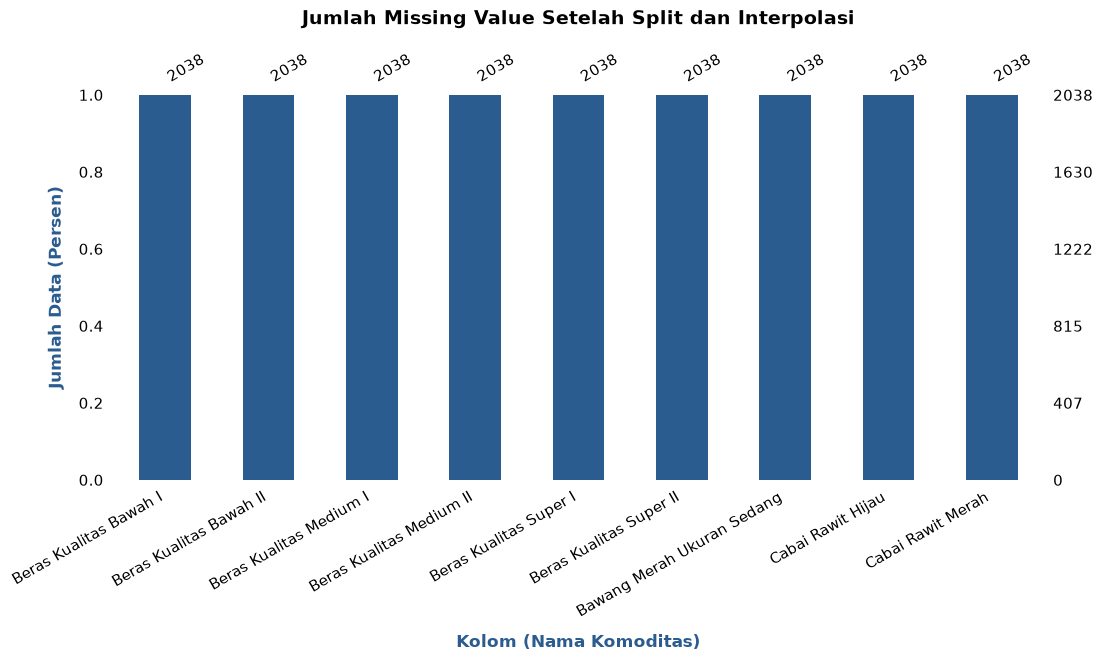

In [11]:
plot_missing_bar(df_cleaned, "Jumlah Missing Value Setelah Split dan Interpolasi")

## Visualisasi Status Stasioneritas


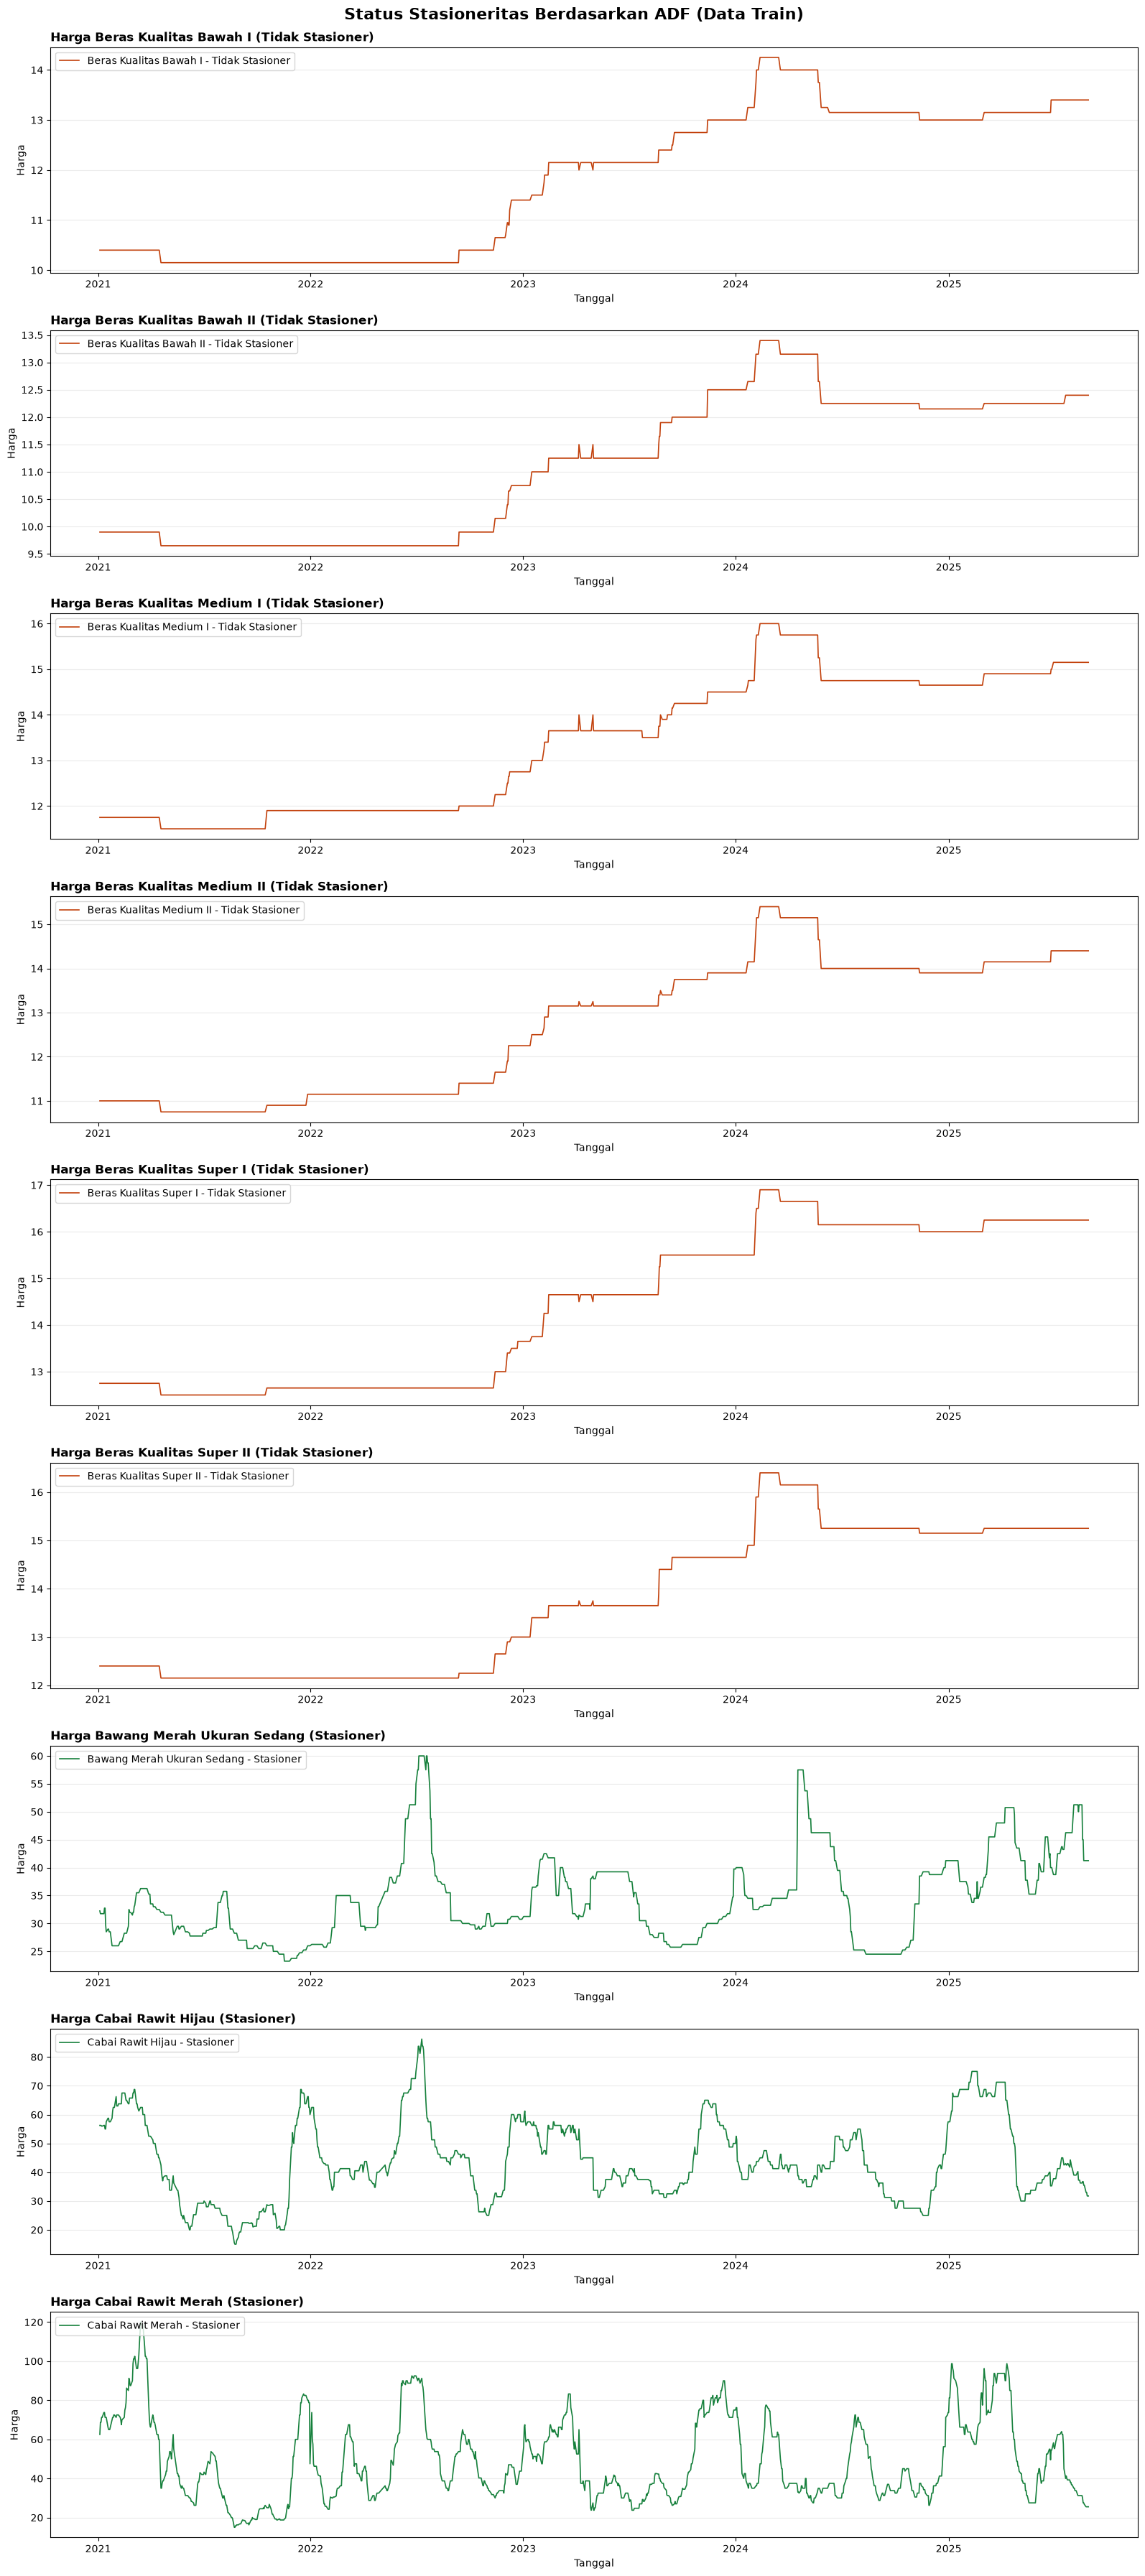

In [12]:
def adf_on_train(col):
    return adfuller(
        df_cleaned.loc[raw_train.index, col].dropna(),
        maxlag=None,
        regression="ct",
        autolag="AIC",
        store=False,
        regresults=False,
        result_object=False,
    )


adf_results = {col: adf_on_train(col) for col in df_cleaned.columns}
eda_stationarity_status = {
    col: "Stasioner" if result[1] < 0.05 else "Tidak Stasioner"
    for col, result in adf_results.items()
}

fig, axes = plt.subplots(
    nrows=len(adf_results),
    ncols=1,
    figsize=(16, 4 * len(adf_results)),
)

for ax, (col, status) in zip(axes, eda_stationarity_status.items()):
    color = "#16803c" if status == "Stasioner" else "#c2410c"
    ax.plot(
        raw_train.index,
        df_cleaned.loc[raw_train.index, col],
        color=color,
        linewidth=1.2,
        label=f"{col} - {status}",
    )
    ax.set_title(f"Harga {col} ({status})", loc="left", fontsize=12, fontweight="bold")
    ax.set_ylabel("Harga")
    ax.set_xlabel("Tanggal")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper left")

fig.suptitle(
    "Status Stasioneritas Berdasarkan ADF (Data Train)",
    fontsize=16,
    fontweight="bold",
    y=0.995,
)
fig.subplots_adjust(hspace=0.6, top=0.97)
plt.tight_layout()
plt.show()

## Memverifikasi Hasil Imputasi Train dan Test


In [13]:
print(df_cleaned.isnull().sum())

Beras Kualitas Bawah I        0
Beras Kualitas Bawah II       0
Beras Kualitas Medium I       0
Beras Kualitas Medium II      0
Beras Kualitas Super I        0
Beras Kualitas Super II       0
Bawang Merah Ukuran Sedang    0
Cabai Rawit Hijau             0
Cabai Rawit Merah             0
dtype: int64


## Memeriksa Persentase Missing Value Setelah Imputasi


In [14]:
feature_miss_value = df_cleaned.isnull().sum() * 100 / len(df_cleaned)
print(feature_miss_value)

Beras Kualitas Bawah I        0.0
Beras Kualitas Bawah II       0.0
Beras Kualitas Medium I       0.0
Beras Kualitas Medium II      0.0
Beras Kualitas Super I        0.0
Beras Kualitas Super II       0.0
Bawang Merah Ukuran Sedang    0.0
Cabai Rawit Hijau             0.0
Cabai Rawit Merah             0.0
dtype: float64


## Uji Stasioneritas dengan ADF


## Menentukan Kolom Komoditas


In [15]:
commodity_cols = df_cleaned.columns.tolist()

## Menjalankan ADF dengan Tren dan Konstanta


In [16]:
for col in commodity_cols:
    result = adf_results[col]
    print(f"ADF Statistic for {col}: {result[0]}")
    print(f"p-value for {col}: {result[1]}")
    if len(result) > 4:
        print("Critical Values for: ")
        for key, value in result[4].items():
            print(f"\t{key}: {value}")
    status = "Stationary" if result[1] < 0.05 else "Non-Stationary"
    print(f"status : {status}")
    print("\n")

ADF Statistic for Beras Kualitas Bawah I: -1.6466364959197806
p-value for Beras Kualitas Bawah I: 0.7736418662615081
Critical Values for: 
	1%: -3.9641336654465316
	5%: -3.413089502928204
	10%: -3.128580413328423
status : Non-Stationary


ADF Statistic for Beras Kualitas Bawah II: -1.5019207602955766
p-value for Beras Kualitas Bawah II: 0.828473889714487
Critical Values for: 
	1%: -3.9641273173653064
	5%: -3.4130864282938935
	10%: -3.1285786037672016
status : Non-Stationary


ADF Statistic for Beras Kualitas Medium I: -2.0848275813746473
p-value for Beras Kualitas Medium I: 0.554581862991379
Critical Values for: 
	1%: -3.9641914824628577
	5%: -3.413117505850037
	10%: -3.128596894250325
status : Non-Stationary


ADF Statistic for Beras Kualitas Medium II: -1.7707217052073123
p-value for Beras Kualitas Medium II: 0.7187017904093482
Critical Values for: 
	1%: -3.9641336654465316
	5%: -3.413089502928204
	10%: -3.128580413328423
status : Non-Stationary


ADF Statistic for Beras Kualitas Sup

## Transformasi Log


In [17]:
log_transformation = FunctionTransformer(
    func=np.log1p, inverse_func=np.expm1, check_inverse=True
)

df_cleaned_log = pd.DataFrame(
    log_transformation.fit_transform(df_cleaned[commodity_cols]),
    index=df_cleaned.index,
    columns=commodity_cols,
)

In [18]:
def log_to_price(log_values):
    """Kembalikan prediksi skala log1p ke skala harga."""
    return np.expm1(np.asarray(log_values, dtype=float).ravel())


data_by_col = {}

for col in commodity_cols:
    data_by_col[col] = {
        "price_train": df_cleaned.loc[raw_train.index, col],
        "price_test": df_cleaned.loc[raw_test.index, col],
        "log_price_train": df_cleaned_log.loc[raw_train.index, col].rename(col),
        "log_price_test": df_cleaned_log.loc[raw_test.index, col].rename(col),
    }
    print(
        f"{col}: ADF={eda_stationarity_status[col]} | "
        f"train {raw_train.index.min().date()} → {raw_train.index.max().date()} | "
        f"test {raw_test.index.min().date()} → {raw_test.index.max().date()}"
    )

Beras Kualitas Bawah I: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Bawah II: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Medium I: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Medium II: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Super I: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Super II: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Bawang Merah Ukuran Sedang: ADF=Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Cabai Rawit Hijau: ADF=Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Cabai Rawit Merah: ADF=Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03


## Feature Engineering


## Menyiapkan Fitur dan Forecaster


In [19]:
horizons = [1, 7, 30]
LAGS = [1, 7, 30]
DIFFERENTIATION = 1  # model memprediksi perubahan harian log harga

window_features = RollingFeatures(
    stats=["mean", "mean", "std", "std", "min", "min", "max", "max"],
    window_sizes=[7, 30, 7, 30, 7, 30, 7, 30],
)
calendar_features = CalendarFeatures(
    features=["day_of_year", "day_of_week", "day_of_month", "month"],
    features_to_encode=["day_of_year", "day_of_month", "day_of_week", "month"],
    encoding="cyclical",
    max_values={
        "day_of_year": 365,
        "day_of_week": 6,
        "day_of_month": 31,
        "month": 12,
    },
)


def make_forecaster(estimator, steps):
    return ForecasterDirect(
        estimator=estimator,
        steps=steps,
        lags=LAGS,
        window_features=window_features,
        calendar_features=calendar_features,
        transformer_y=StandardScaler(),
        differentiation=DIFFERENTIATION,
    )


def prediction_column(predictions):
    return "pred" if "pred" in predictions.columns else predictions.columns[0]

## Melatih Model Baseline (Parameter Default)


In [20]:
forecasters_default = {}

for col in commodity_cols:
    forecasters_default[col] = {}
    for h in horizons:
        forecaster_default = make_forecaster(lgb.LGBMRegressor(force_col_wise=True), h)
        forecaster_default.fit(y=data_by_col[col]["log_price_train"])
        forecasters_default[col][h] = forecaster_default

[LightGBM] [Info] Total Bins 910
[LightGBM] [Info] Number of data points in the train set: 1668, number of used features: 19
[LightGBM] [Info] Start training from score 0.001259
[LightGBM] [Info] Total Bins 910
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 910
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 911
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 911
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 911
[LightGBM] [Info] Number of data points in the train set: 1662, number of use

## Mencari Hyperparameter dengan Genetic Algorithm


## Menentukan Fitness Function GA


In [21]:
GENE_SPACE = [
    {"low": 7, "high": 31},  # num_leaves
    {"low": 0.01, "high": 0.1},  # learning_rate
    {"low": 3, "high": 6},  # max_depth
    {"low": 50, "high": 200},  # n_estimators
    {"low": 5, "high": 100},  # min_child_samples
    {"low": 0.6, "high": 0.9},  # subsample
    {"low": 0.6, "high": 0.9},  # colsample_bytree
    {"low": 0.1, "high": 10.0},  # min_child_weight
    {"low": 0.0, "high": 10.0},  # reg_alpha
    {"low": 0.0, "high": 10.0},  # reg_lambda
    {"low": 0.01, "high": 0.5},  # min_split_gain
]


def build_lgbm_params(solution):
    return {
        "objective": "regression_l1",
        "num_leaves": int(solution[0]),
        "learning_rate": solution[1],
        "max_depth": int(solution[2]),
        "n_estimators": int(solution[3]),
        "min_child_samples": int(solution[4]),
        "subsample": solution[5],
        "colsample_bytree": solution[6],
        "min_child_weight": solution[7],
        "reg_alpha": solution[8],
        "reg_lambda": solution[9],
        "min_split_gain": solution[10],
        "bagging_freq": 1,
        "verbosity": -1,
    }


def running_for_ga(
    y,
    steps,
    gene_space=GENE_SPACE,
    build_params=build_lgbm_params,
    make_estimator=lgb.LGBMRegressor,
):
    validation_window = max(30, steps)
    genetic_algorithm_search_split = TimeSeriesSplit(
        n_splits=4, test_size=validation_window, max_train_size=1630
    )

    def fitness_function(ga_instance, solution, solution_idx):
        params = build_params(solution)
        mae_scores = []
        try:
            for train_idx, test_idx in genetic_algorithm_search_split.split(y):
                y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
                y_fold = pd.concat([y_train, y_test])
                cv = TimeSeriesFold(
                    steps=steps,
                    initial_train_size=len(y_train),
                    refit=False,
                    fixed_train_size=False,
                    allow_incomplete_fold=True,
                    differentiation=DIFFERENTIATION,
                    verbose=False,
                )
                _, predictions = backtesting_forecaster(
                    forecaster=make_forecaster(make_estimator(**params), steps),
                    y=y_fold,
                    cv=cv,
                    metric="mean_absolute_error",
                    verbose=False,
                    show_progress=False,
                )
                y_actual = y_fold.reindex(predictions.index)
                mae_scores.append(
                    mean_absolute_error(
                        y_actual, predictions[prediction_column(predictions)]
                    )
                )
            return -float(np.mean(mae_scores))
        except Exception as error:
            print(f"Error for solution {solution_idx}: {error}")
            return -999.0

    def on_generation(ga_instance):
        best_fitness = np.max(ga_instance.last_generation_fitness)
        print(
            f"Generation {ga_instance.generations_completed}: "
            f"Best MAE (skala log harga) = {-best_fitness:.6f}"
        )

    genetic_algorithm_instance = pygad.GA(
        num_generations=8,
        sol_per_pop=16,
        num_parents_mating=8,
        num_genes=len(gene_space),
        fitness_func=fitness_function,
        gene_space=gene_space,
        on_generation=on_generation,
        parent_selection_type="tournament",
        crossover_type="single_point",
        crossover_probability=0.8,
        mutation_type="random",
        mutation_percent_genes=15,
        keep_elitism=2,
        random_seed=42,
    )

    genetic_algorithm_instance.run()
    return genetic_algorithm_instance.best_solution()

In [22]:
best_params_for_GA = {}
forecasters_ga = {}

for col in commodity_cols:
    model_train = data_by_col[col]["log_price_train"]
    price_test = data_by_col[col]["price_test"]

    print(
        f"{col}: train {model_train.index.min().date()} → "
        f"{model_train.index.max().date()} | test {price_test.index.min().date()} → "
        f"{price_test.index.max().date()}"
    )

    best_params_for_GA[col] = {}
    forecasters_ga[col] = {}

    for h in horizons:
        best_solution, best_solution_fitness, best_solution_idx = running_for_ga(
            y=model_train, steps=h
        )
        params = build_lgbm_params(best_solution)
        best_params_for_GA[col][h] = {
            "params": params,
            "fitness": best_solution_fitness,
            "solution_index": best_solution_idx,
        }

        forecaster_ga = make_forecaster(lgb.LGBMRegressor(**params), h)
        forecaster_ga.fit(y=model_train)
        forecasters_ga[col][h] = forecaster_ga

Beras Kualitas Bawah I: train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Generation 1: Best MAE (skala log harga) = 0.000146
Generation 2: Best MAE (skala log harga) = 0.000146
Generation 3: Best MAE (skala log harga) = 0.000146
Generation 4: Best MAE (skala log harga) = 0.000146
Generation 5: Best MAE (skala log harga) = 0.000146
Generation 6: Best MAE (skala log harga) = 0.000146
Generation 7: Best MAE (skala log harga) = 0.000146
Generation 8: Best MAE (skala log harga) = 0.000146
Generation 1: Best MAE (skala log harga) = 0.000438
Generation 2: Best MAE (skala log harga) = 0.000438
Generation 3: Best MAE (skala log harga) = 0.000438
Generation 4: Best MAE (skala log harga) = 0.000438
Generation 5: Best MAE (skala log harga) = 0.000438
Generation 6: Best MAE (skala log harga) = 0.000438
Generation 7: Best MAE (skala log harga) = 0.000438
Generation 8: Best MAE (skala log harga) = 0.000438
Generation 1: Best MAE (skala log harga) = 0.000730
Generation 2: Best MAE (skala l

## Menampilkan Hyperparameter Terbaik


In [23]:
for commodity, params_h in best_params_for_GA.items():
    print("\n" + "=" * 72)
    print(f"Nama Komoditas: {commodity}")
    print("=" * 72)

    for h in horizons:
        print(f"\nBest parameters for horizon {h}:")
        for key, value in params_h[h]["params"].items():
            if isinstance(value, float):
                print(f"{key:20s}: {value:.6f}")
            else:
                print(f"{key:20s}: {value}")


Nama Komoditas: Beras Kualitas Bawah I

Best parameters for horizon 1:
objective           : regression_l1
num_leaves          : 27
learning_rate       : 0.038870
max_depth           : 5
n_estimators        : 141
min_child_samples   : 88
subsample           : 0.841860
colsample_bytree    : 0.606381
min_child_weight    : 4.319195
reg_alpha           : 8.736771
reg_lambda          : 1.448949
min_split_gain      : 0.084321
bagging_freq        : 1
verbosity           : -1

Best parameters for horizon 7:
objective           : regression_l1
num_leaves          : 27
learning_rate       : 0.038870
max_depth           : 5
n_estimators        : 141
min_child_samples   : 88
subsample           : 0.841860
colsample_bytree    : 0.606381
min_child_weight    : 4.319195
reg_alpha           : 8.736771
reg_lambda          : 1.448949
min_split_gain      : 0.084321
bagging_freq        : 1
verbosity           : -1

Best parameters for horizon 30:
objective           : regression_l1
num_leaves          : 2

## Menyimpan Hyperparameter dan Forecaster GA


In [24]:
def save_forecasters(forecasters, folder, prefix):
    Path(folder).mkdir(exist_ok=True)
    for col in commodity_cols:
        for h in horizons:
            save_forecaster(
                forecasters[col][h],
                str(Path(folder) / f"{prefix}_{col}_h{h}.joblib"),
                save_custom_functions=False,
            )
            print("tersimpan:", col, "h=" + str(h))


Path("params").mkdir(exist_ok=True)
jl.dump(best_params_for_GA, "params/best_params_lgbm.pkl")
save_forecasters(forecasters_ga, "tuned_lgbm", "tuned_lgbm")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te

## Evaluasi pada Data Test


## Meninjau Rentang Train dan Test


In [25]:
for col in commodity_cols:
    model_train = data_by_col[col]["log_price_train"]
    price_test = data_by_col[col]["price_test"]
    print(
        f"{col}: train {model_train.index.min().date()} -> "
        f"{model_train.index.max().date()} | test {price_test.index.min().date()} -> "
        f"{price_test.index.max().date()}"
    )

Beras Kualitas Bawah I: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Bawah II: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Medium I: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Medium II: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Super I: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Super II: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Bawang Merah Ukuran Sedang: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Cabai Rawit Hijau: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Cabai Rawit Merah: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03


## Contoh: Melatih Forecaster untuk Evaluasi


In [26]:
col, h = commodity_cols[-1], horizons[-1]  # contoh: satu komoditas & horizon
y_train = data_by_col[col]["log_price_train"]
forecaster_eval = make_forecaster(
    lgb.LGBMRegressor(**best_params_for_GA[col][h]["params"]), h
)
forecaster_eval.fit(y=y_train)

## Contoh: Memprediksi Data Test


In [27]:
prediction = forecaster_eval.predict(steps=h)
test_index_h = data_by_col[col]["price_test"].index[:h]

## Contoh: Mengembalikan Prediksi ke Skala Harga


In [28]:
price_pred = log_to_price(prediction)
actual_price = data_by_col[col]["price_test"].iloc[:h].to_numpy()

## Mengevaluasi Semua Komoditas


In [29]:
forecasters_eval = {}
eval_rows = []

for col in commodity_cols:
    price_test = data_by_col[col]["price_test"]
    forecasters_eval[col] = {}
    for h in horizons:
        forecaster_eval = make_forecaster(
            lgb.LGBMRegressor(**best_params_for_GA[col][h]["params"]), h
        )
        forecaster_eval.fit(y=data_by_col[col]["log_price_train"])
        forecasters_eval[col][h] = forecaster_eval

        price_pred = log_to_price(forecaster_eval.predict(steps=h))
        actual_price = price_test.iloc[:h].to_numpy()
        eval_rows.append(
            {
                "Komoditas": col,
                "Horizon": h,
                "MAE": mean_absolute_error(actual_price, price_pred),
                "RMSE": root_mean_squared_error(actual_price, price_pred),
                "MAPE (%)": mean_absolute_percentage_error(actual_price, price_pred)
                * 100,
            }
        )

df_eval = pd.DataFrame(eval_rows)
df_eval

,Komoditas,Horizon,MAE,RMSE,MAPE (%)
0,Beras Kualitas Bawah I,1,1.776357e-15,1.776357e-15,1.325639e-14
1,Beras Kualitas Bawah I,7,1.776357e-15,1.776357e-15,1.325639e-14
2,Beras Kualitas Bawah I,30,1.750000e-01,2.091650e-01,1.330798e+00
3,Beras Kualitas Bawah II,1,0.000000e+00,0.000000e+00,0.000000e+00
4,Beras Kualitas Bawah II,7,0.000000e+00,0.000000e+00,0.000000e+00
5,Beras Kualitas Bawah II,30,1.750000e-01,2.091650e-01,1.440329e+00
6,Beras Kualitas Medium I,1,0.000000e+00,0.000000e+00,0.000000e+00
7,Beras Kualitas Medium I,7,0.000000e+00,0.000000e+00,0.000000e+00
8,Beras Kualitas Medium I,30,1.750000e-01,2.091650e-01,1.174497e+00
9,Beras Kualitas Medium II,1,1.776357e-15,1.776357e-15,1.233581e-14


## Backtesting Walk-forward


In [30]:
wf_rows = []
wf_plot_rows = []

for col in commodity_cols:
    log_price_train = data_by_col[col]["log_price_train"]
    y_walk_forward = pd.concat(
        [log_price_train, data_by_col[col]["log_price_test"]]
    ).asfreq("D")

    for h in horizons:
        cv = TimeSeriesFold(
            steps=h,
            initial_train_size=len(log_price_train),
            refit=True,
            fixed_train_size=False,
            allow_incomplete_fold=True,
            differentiation=DIFFERENTIATION,
            verbose=False,
        )
        _, predictions = backtesting_forecaster(
            forecaster=make_forecaster(
                lgb.LGBMRegressor(**best_params_for_GA[col][h]["params"]), h
            ),
            y=y_walk_forward,
            cv=cv,
            metric="mean_absolute_error",
            verbose=False,
            show_progress=False,
        )

        idx = predictions.index
        price_predicted = log_to_price(predictions[prediction_column(predictions)])
        raw_actual = raw_test[col].reindex(idx)
        real_mask = raw_actual.notna().to_numpy()
        price_actual = raw_actual.to_numpy()[real_mask]
        price_predicted = price_predicted[real_mask]

        wf_rows.append(
            {
                "Komoditas": col,
                "Horizon": h,
                "Jumlah Observasi": int(real_mask.sum()),
                "MAE": mean_absolute_error(price_actual, price_predicted),
                "RMSE": root_mean_squared_error(price_actual, price_predicted),
                "MAPE (%)": mean_absolute_percentage_error(
                    price_actual, price_predicted
                )
                * 100,
            }
        )
        wf_plot_rows.extend(
            {
                "Tanggal": tanggal,
                "Komoditas": col,
                "Horizon": h,
                "Harga Aktual": actual,
                "Harga Prediksi": predicted,
            }
            for tanggal, actual, predicted in zip(
                idx[real_mask], price_actual, price_predicted
            )
        )

df_walkforward = pd.DataFrame(wf_rows)
df_walkforward_predictions = pd.DataFrame(wf_plot_rows)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df_walkforward

,Komoditas,Horizon,Jumlah Observasi,MAE,RMSE,MAPE (%)
0,Beras Kualitas Bawah I,1,241,0.0015,0.0173,0.0110
1,Beras Kualitas Bawah I,7,241,0.0060,0.0371,0.0457
2,Beras Kualitas Bawah I,30,241,0.0180,0.0643,0.1371
3,Beras Kualitas Bawah II,1,241,0.0010,0.0161,0.0085
4,Beras Kualitas Bawah II,7,241,0.0052,0.0360,0.0427
5,Beras Kualitas Bawah II,30,241,0.0156,0.0624,0.1281
6,Beras Kualitas Medium I,1,241,0.0015,0.0173,0.0100
7,Beras Kualitas Medium I,7,241,0.0060,0.0371,0.0403
8,Beras Kualitas Medium I,30,241,0.0180,0.0643,0.1210
9,Beras Kualitas Medium II,1,241,0.0015,0.0173,0.0102


## Plot Harga Aktual vs Prediksi Walk-forward


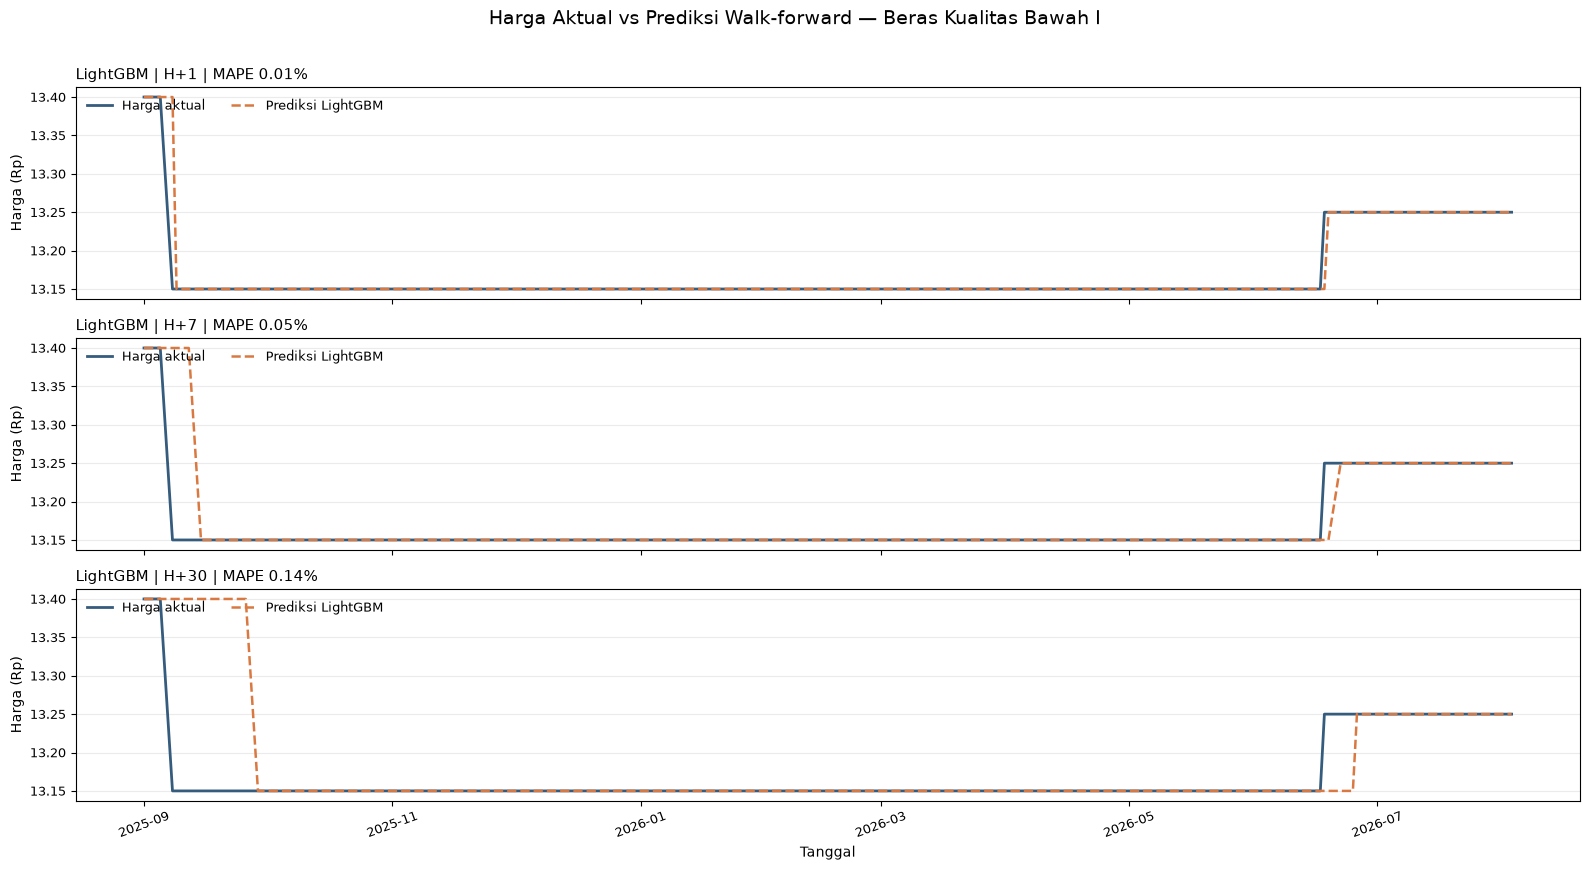

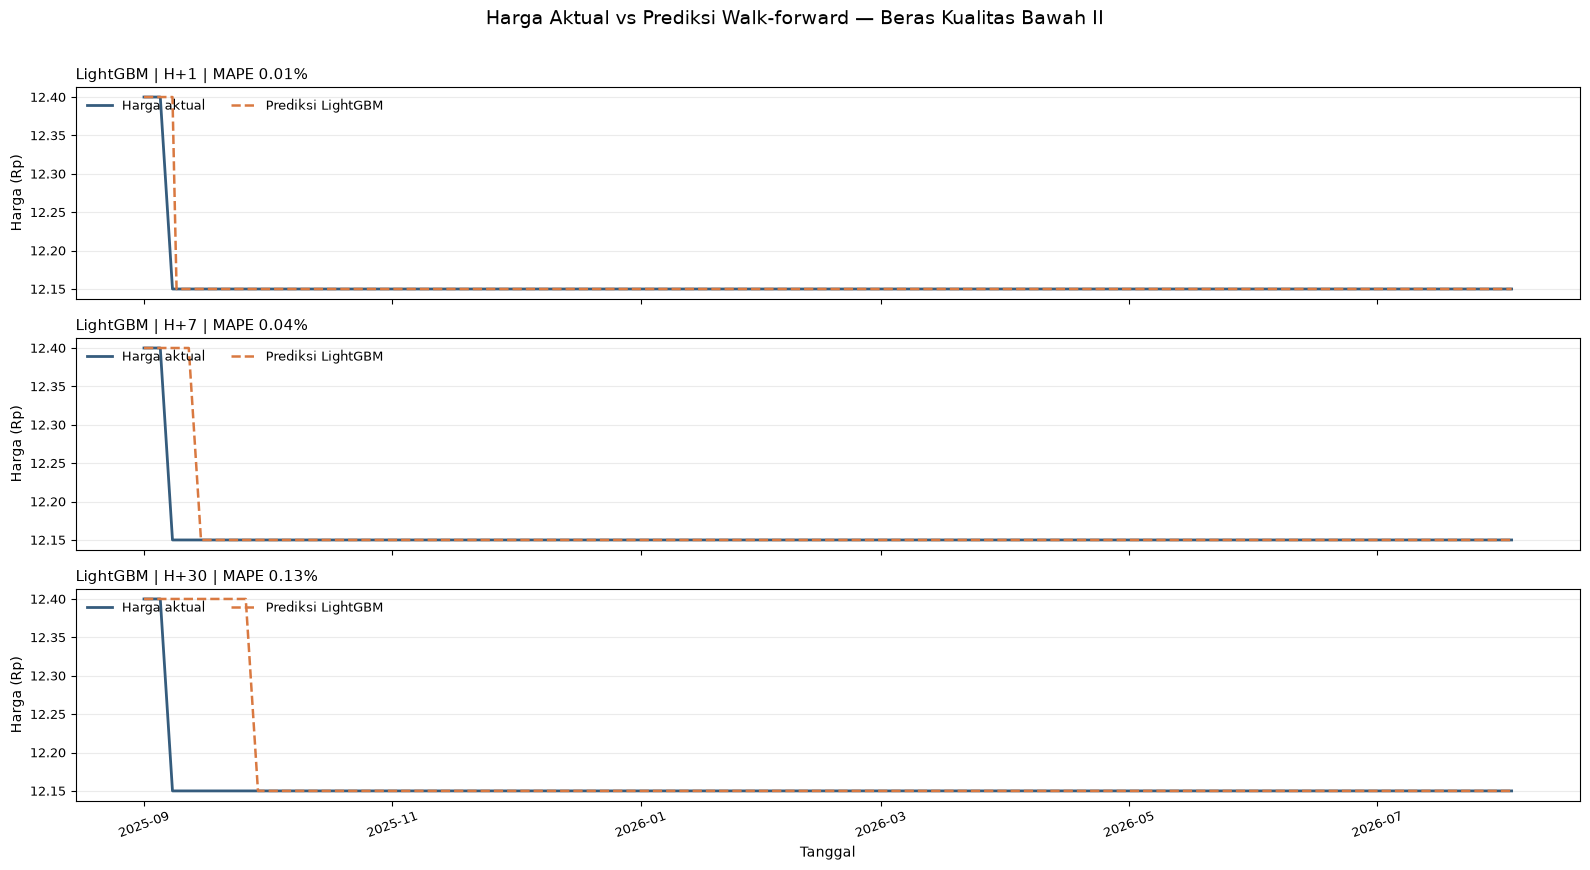

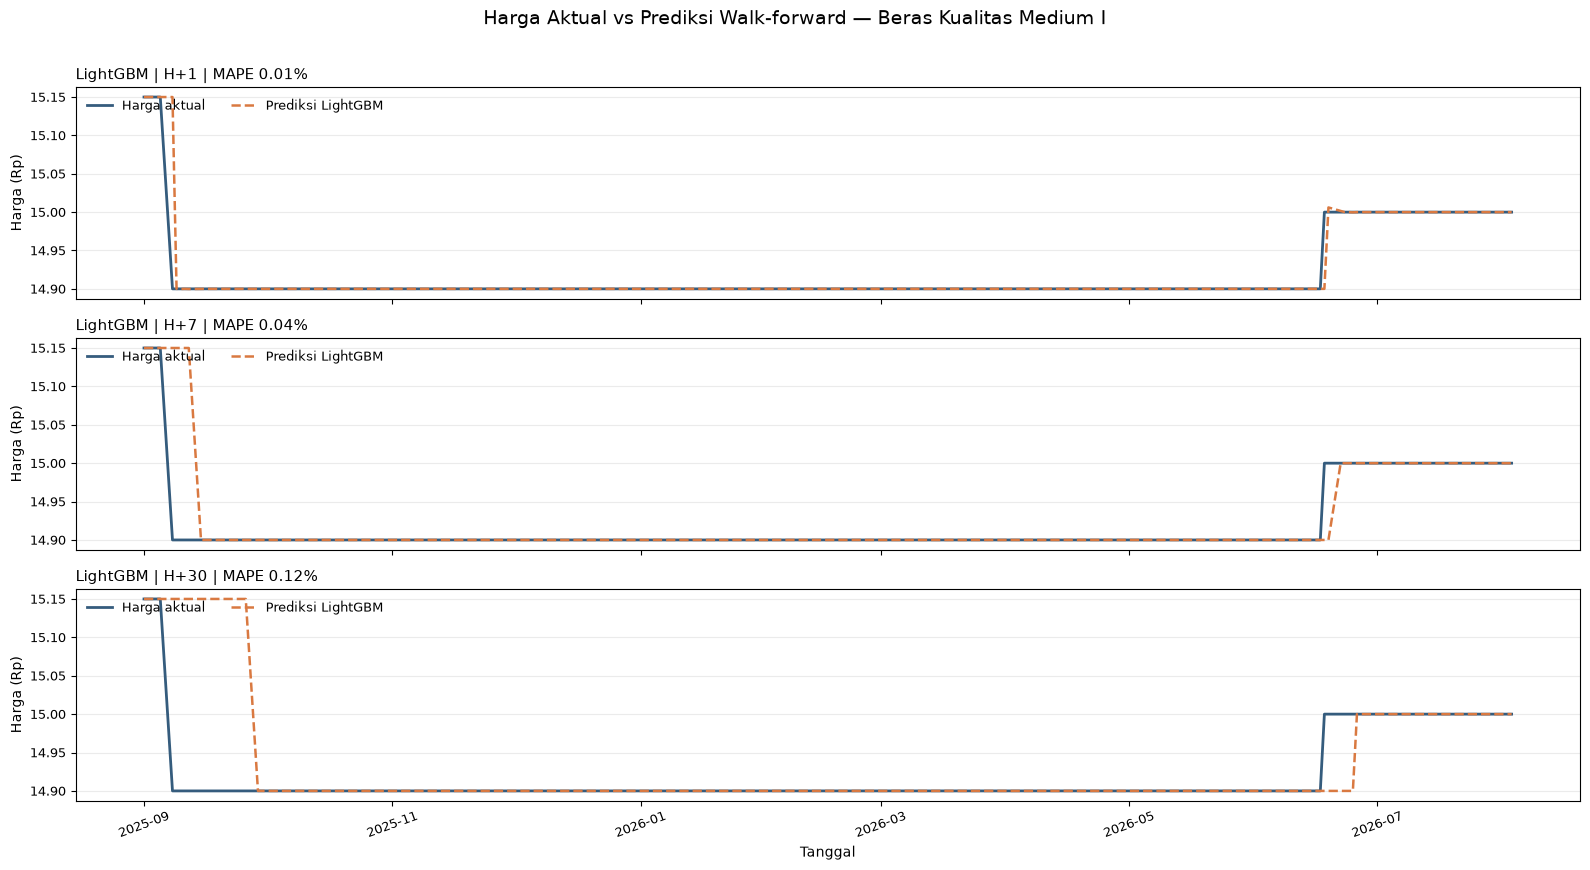

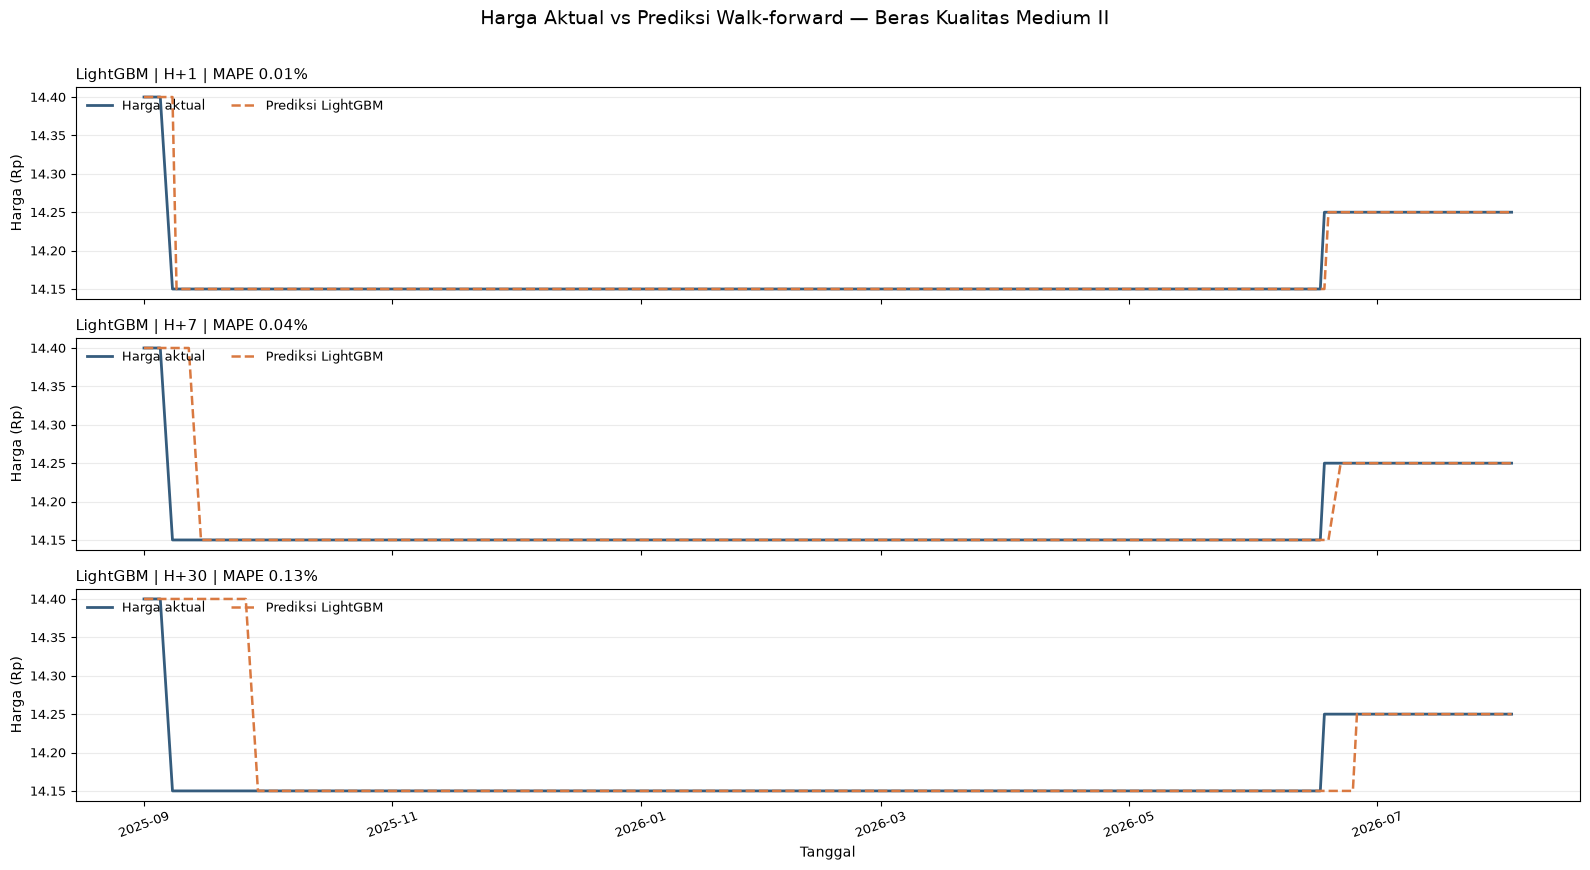

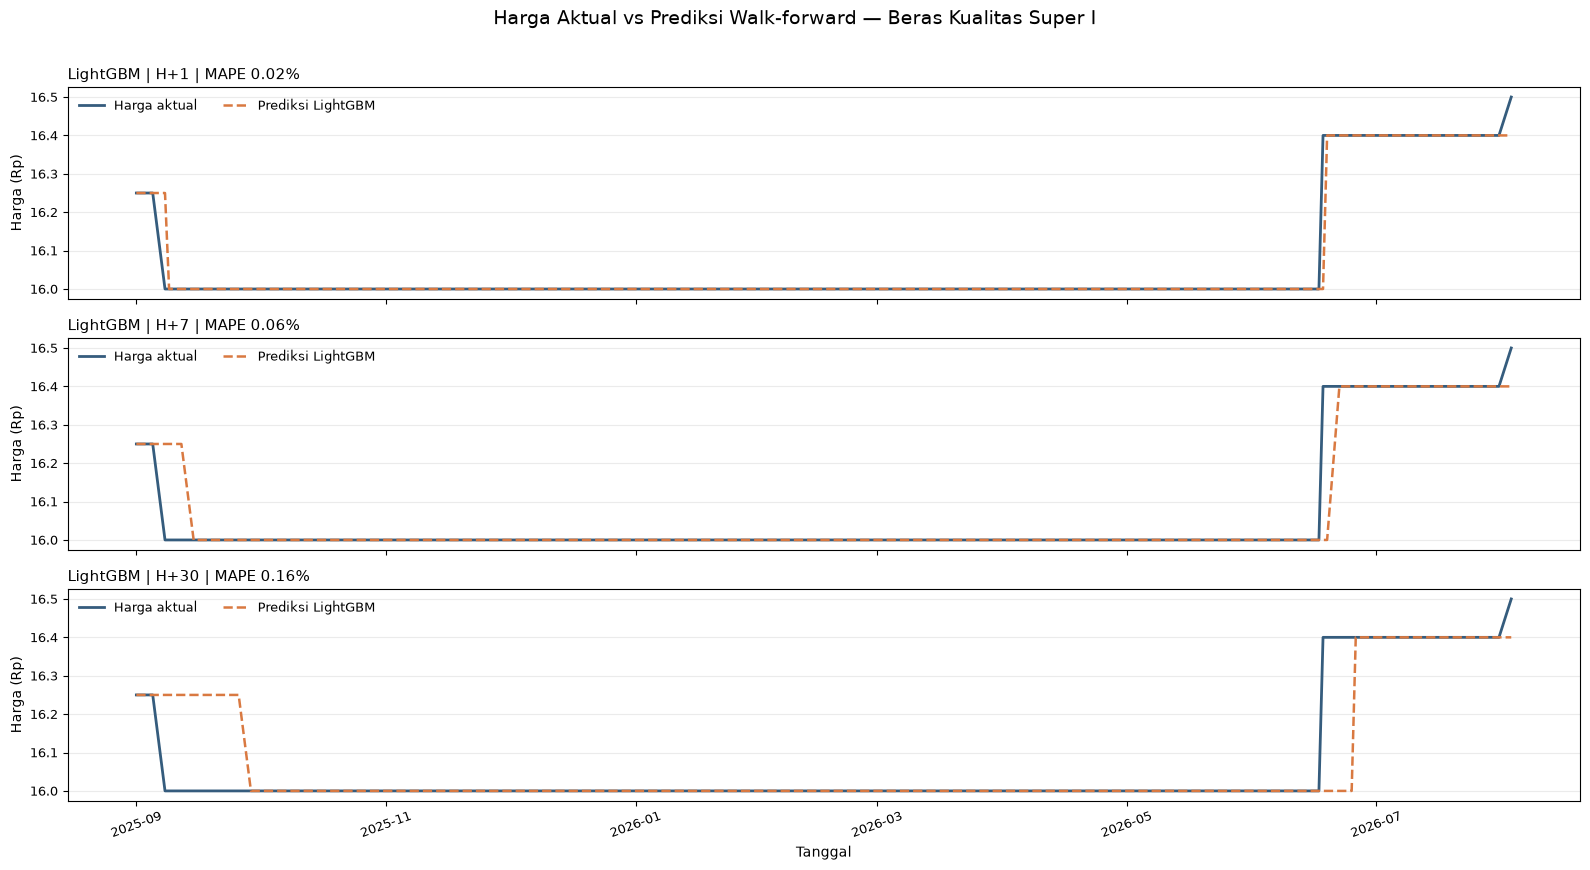

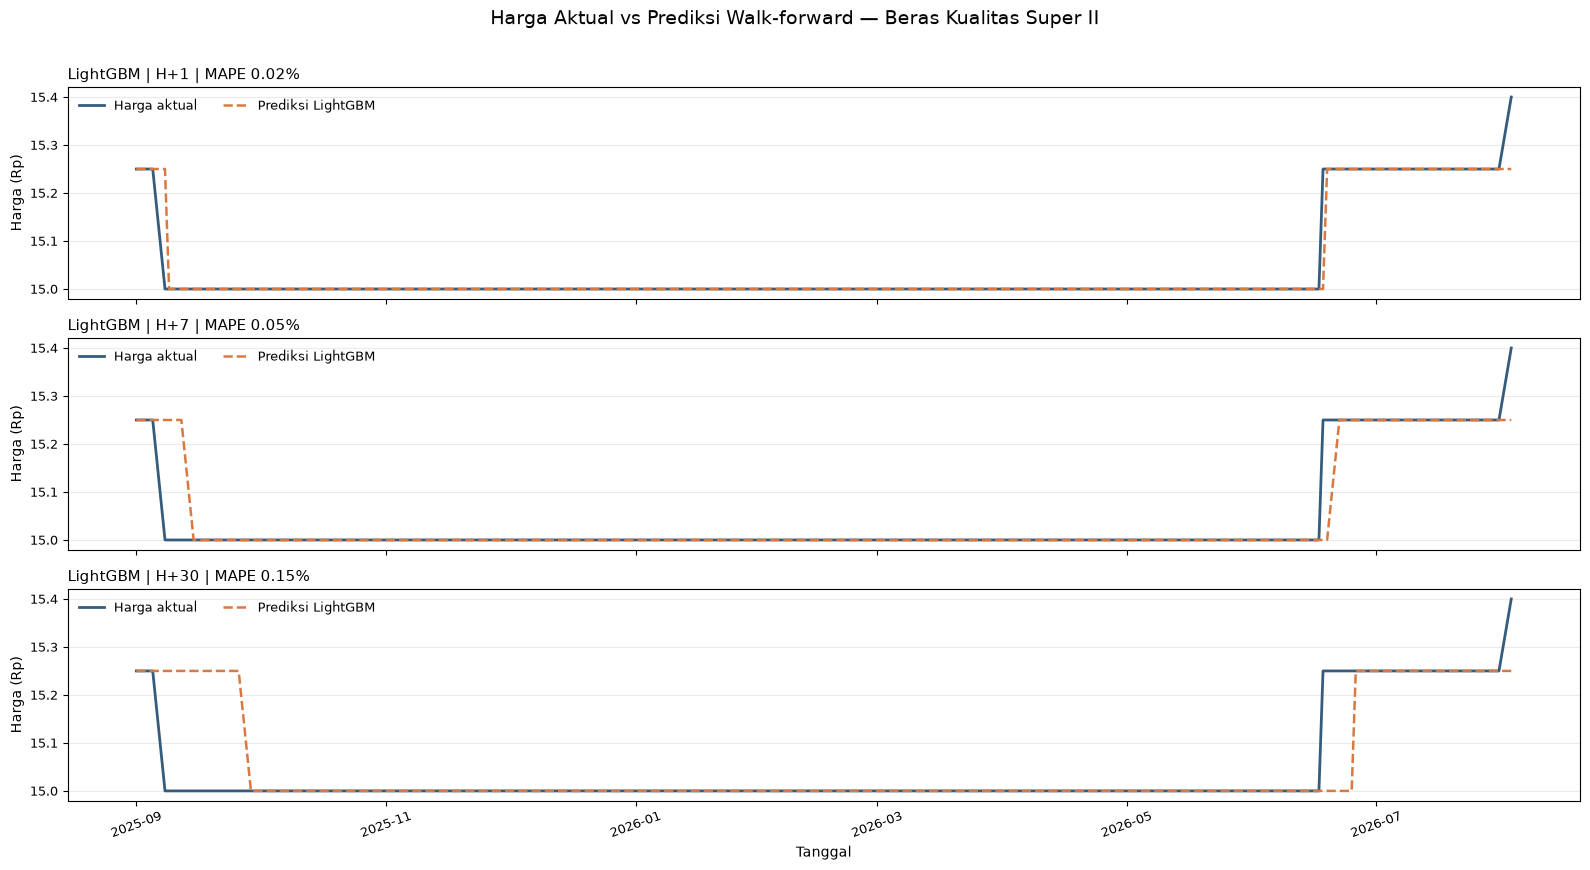

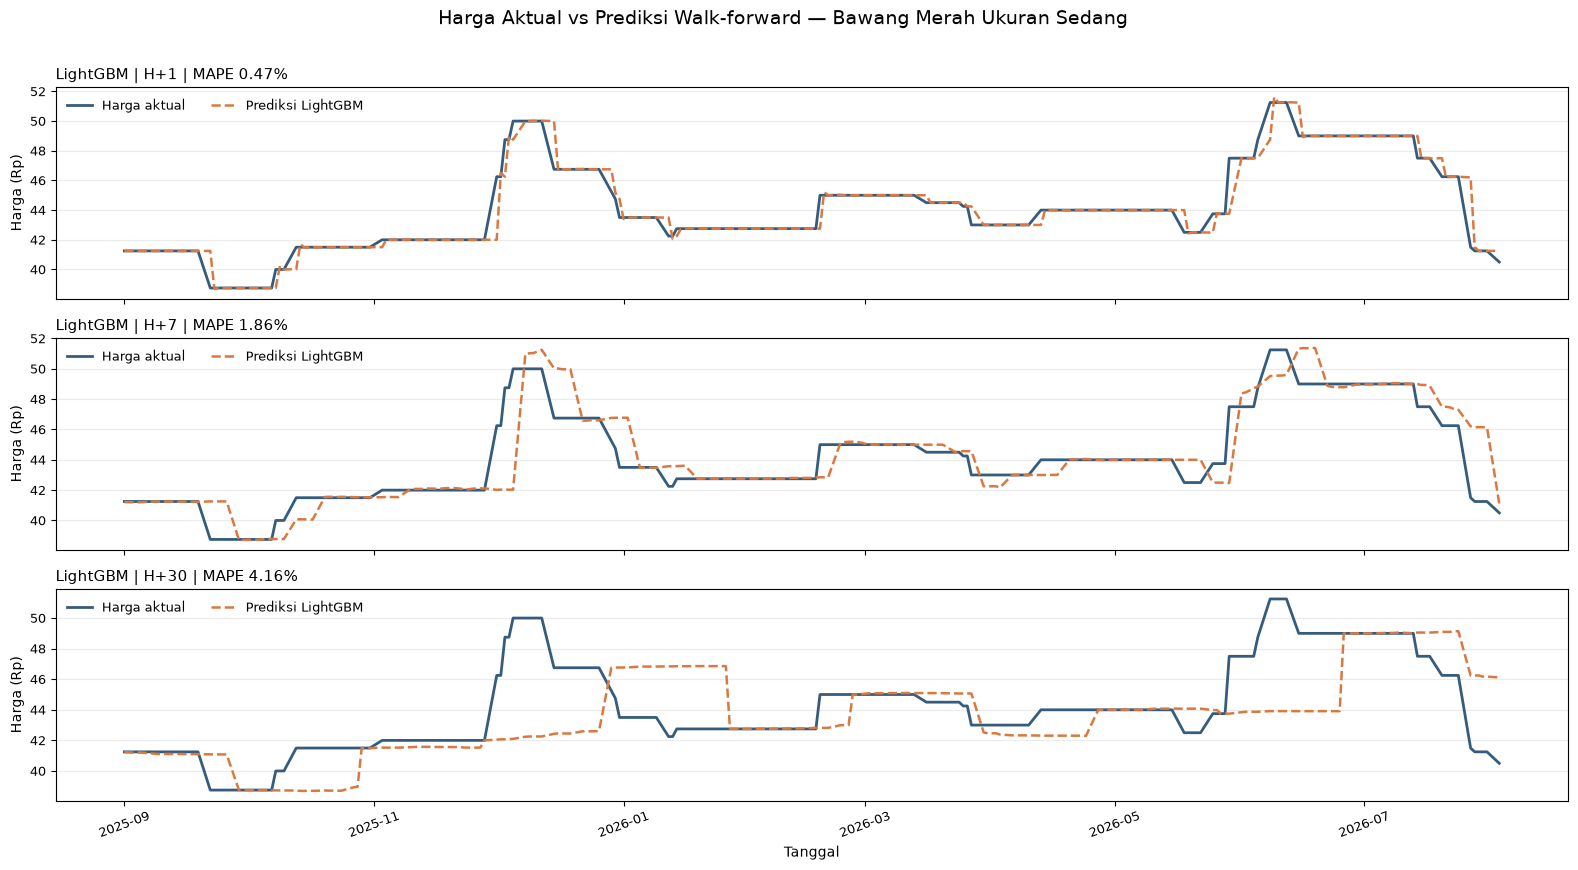

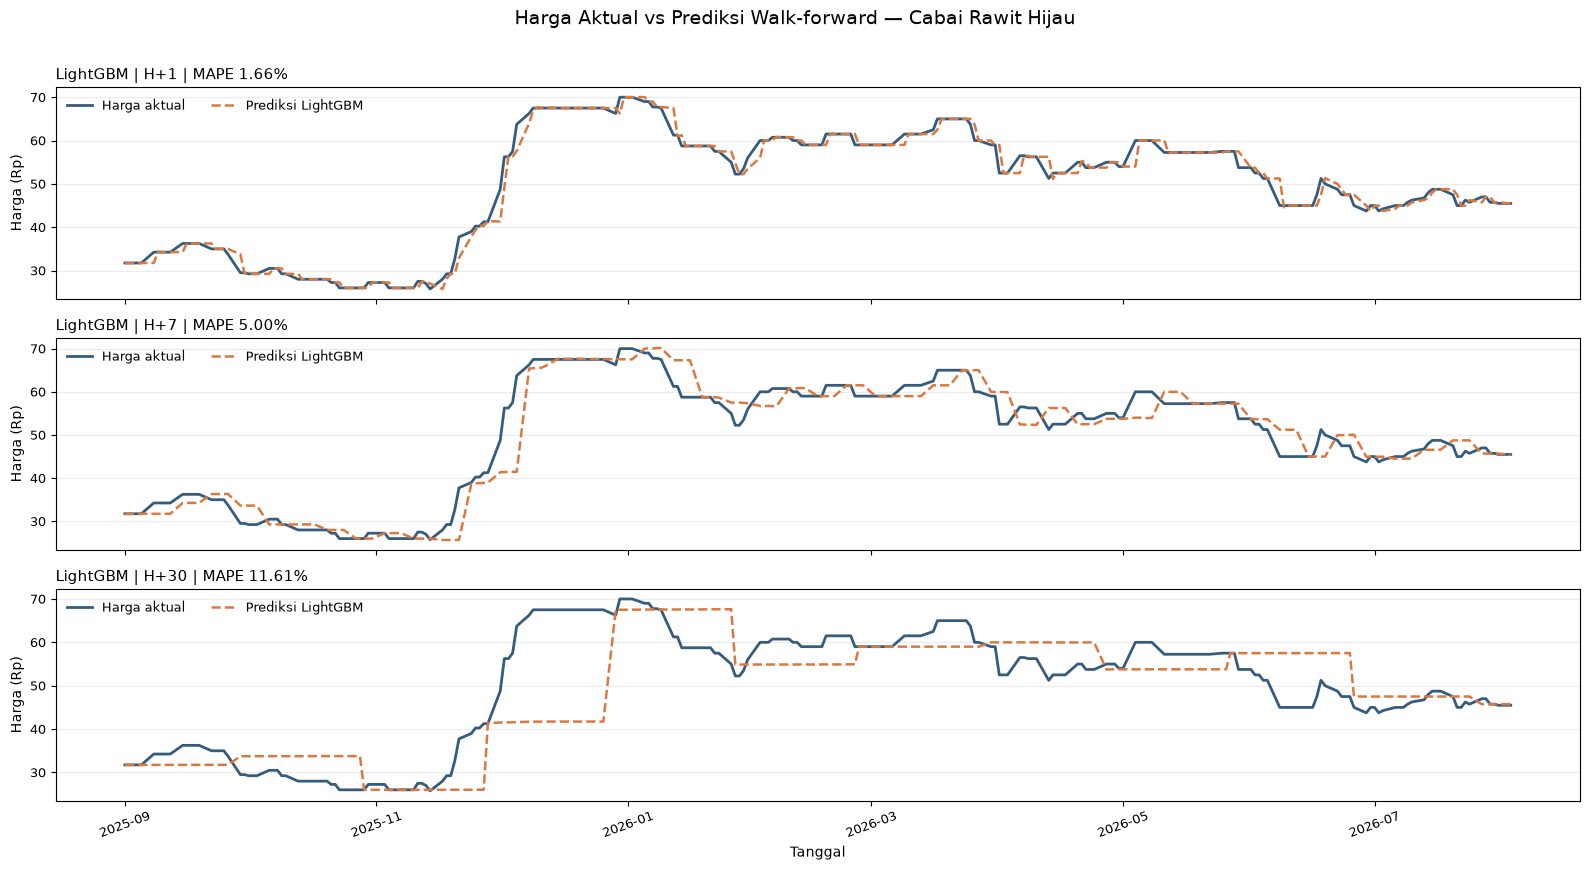

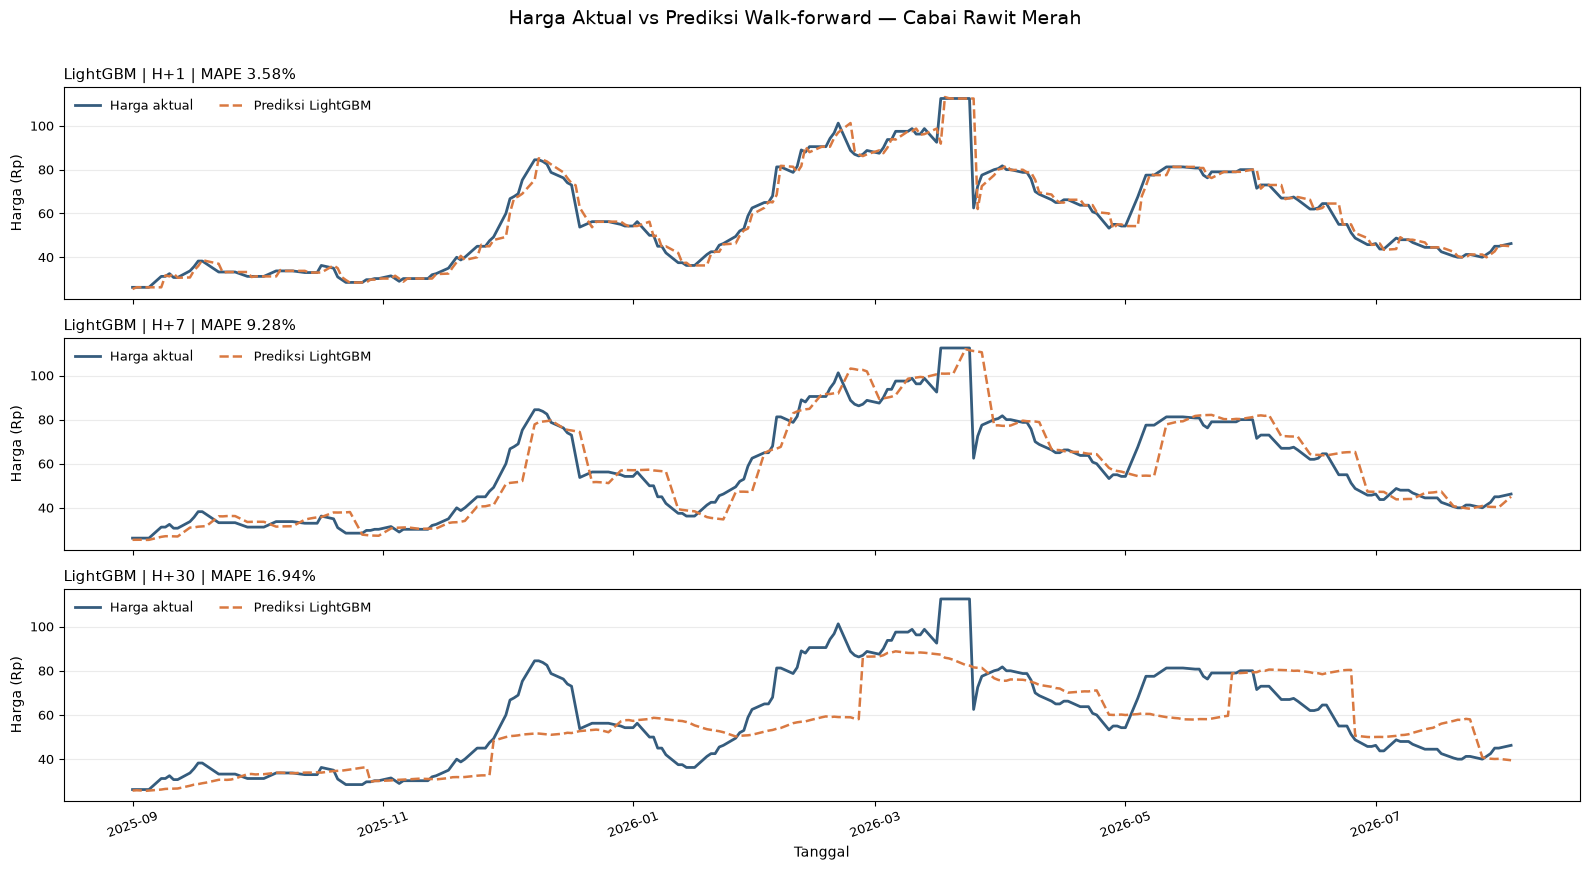

In [31]:
WARNA_MODEL = {"LightGBM": "#d97941", "XGBoost": "#2b5c8f"}


def plot_walkforward(prediksi_per_model, judul_utama, lebar=16, tinggi_panel=2.9):
    kombinasi = [(h, nama) for h in horizons for nama in prediksi_per_model]

    for col in commodity_cols:
        fig, axes = plt.subplots(
            nrows=len(kombinasi),
            ncols=1,
            figsize=(lebar, tinggi_panel * len(kombinasi)),
            sharex=True,
            squeeze=False,
        )

        for row_idx, (h, nama_model) in enumerate(kombinasi):
            ax = axes[row_idx, 0]
            df_pred = prediksi_per_model[nama_model]
            panel = df_pred.loc[
                (df_pred["Komoditas"] == col) & (df_pred["Horizon"] == h)
            ].sort_values("Tanggal")

            if panel.empty:
                ax.text(0.5, 0.5, "Tidak ada observasi", ha="center", va="center")
                ax.set_axis_off()
                continue

            ax.plot(
                panel["Tanggal"],
                panel["Harga Aktual"],
                color="#355c7d",
                linewidth=2.0,
                label="Harga aktual",
            )
            ax.plot(
                panel["Tanggal"],
                panel["Harga Prediksi"],
                color=WARNA_MODEL.get(nama_model, "#8c564b"),
                linewidth=1.8,
                linestyle="--",
                label=f"Prediksi {nama_model}",
            )

            mape_panel = (
                abs(panel["Harga Prediksi"] - panel["Harga Aktual"])
                / panel["Harga Aktual"]
            ).mean() * 100
            ax.set_title(
                f"{nama_model} | H+{h} | MAPE {mape_panel:.2f}%",
                fontsize=11,
                loc="left",
            )
            ax.set_ylabel("Harga (Rp)", fontsize=10)
            ax.grid(axis="y", alpha=0.25)
            ax.tick_params(axis="both", labelsize=9)
            ax.legend(loc="upper left", fontsize=9, frameon=False, ncol=2)

        axes[-1, 0].set_xlabel("Tanggal", fontsize=10)
        axes[-1, 0].tick_params(axis="x", labelrotation=20, labelsize=9)
        fig.suptitle(f"{judul_utama} — {col}", fontsize=14, y=0.995)
        fig.tight_layout(rect=(0, 0, 1, 0.985))
        plt.show()


plot_walkforward(
    {"LightGBM": df_walkforward_predictions},
    "Harga Aktual vs Prediksi Walk-forward",
)

## Early Warning System H+30


In [32]:
THRESHOLD = {"Bahaya": 20, "Warning": 10, "Waspada": 5}  # urut dari paling berat
h_ews = 30


def ews_status(persen):
    for status, batas in THRESHOLD.items():
        if persen > batas:
            return status
    return "Normal"


ews_rows = []

for col in commodity_cols:
    price_train = data_by_col[col]["price_train"]
    harga_origin = float(price_train.iloc[-1])
    harga_pred = log_to_price(forecasters_eval[col][h_ews].predict(steps=h_ews))
    harga_h30 = float(harga_pred[-1])
    persen = (harga_h30 - harga_origin) / harga_origin * 100

    ews_rows.append(
        {
            "Komoditas": col,
            "Tanggal origin": price_train.index[-1].date(),
            "Harga origin (train)": harga_origin,
            "Prediksi H+30": harga_h30,
            "Perubahan (%)": persen,
            "Status": ews_status(persen),
        }
    )

df_ews = pd.DataFrame(ews_rows)
df_ews

,Komoditas,Tanggal origin,Harga origin (train),Prediksi H+30,Perubahan (%),Status
0,Beras Kualitas Bawah I,2025-08-29,13.4000,13.4000,-0.0000,Normal
1,Beras Kualitas Bawah II,2025-08-29,12.4000,12.4000,0.0000,Normal
2,Beras Kualitas Medium I,2025-08-29,15.1500,15.1500,0.0000,Normal
3,Beras Kualitas Medium II,2025-08-29,14.4000,14.4000,0.0000,Normal
4,Beras Kualitas Super I,2025-08-29,16.2500,16.2500,0.0000,Normal
5,Beras Kualitas Super II,2025-08-29,15.2500,15.2500,0.0000,Normal
6,Bawang Merah Ukuran Sedang,2025-08-29,41.2500,41.0820,-0.4073,Normal
7,Cabai Rawit Hijau,2025-08-29,31.7500,31.7645,0.0457,Normal
8,Cabai Rawit Merah,2025-08-29,25.5000,32.2507,26.4735,Bahaya


## Menyimpan Final Model


In [33]:
save_forecasters(forecasters_ga, "final_lgbm", "final_lgbm")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te

## Model Pembanding: XGBoost


In [34]:
GENE_SPACE_XGB = [
    {"low": 3, "high": 6},  # max_depth
    {"low": 0.01, "high": 0.1},  # learning_rate
    {"low": 50, "high": 200},  # n_estimators
    {"low": 0.1, "high": 10.0},  # min_child_weight
    {"low": 0.6, "high": 0.9},  # subsample
    {"low": 0.6, "high": 0.9},  # colsample_bytree
    {"low": 0.6, "high": 1.0},  # colsample_bylevel
    {"low": 0.0, "high": 10.0},  # reg_alpha
    {"low": 0.0, "high": 10.0},  # reg_lambda
    {"low": 0.01, "high": 0.5},  # gamma (padanan min_split_gain)
]


def build_xgb_params(solution):
    return {
        "objective": "reg:absoluteerror",  # padanan regression_l1 pada LightGBM
        "max_depth": int(solution[0]),
        "learning_rate": solution[1],
        "n_estimators": int(solution[2]),
        "min_child_weight": solution[3],
        "subsample": solution[4],
        "colsample_bytree": solution[5],
        "colsample_bylevel": solution[6],
        "reg_alpha": solution[7],
        "reg_lambda": solution[8],
        "gamma": solution[9],
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": 42,
        "verbosity": 0,
    }


# sanity check: tiap gen terpakai dan estimator bisa dibentuk
probe_params = build_xgb_params([gene["low"] for gene in GENE_SPACE_XGB])
assert probe_params["max_depth"] == 3 and probe_params["n_estimators"] == 50
assert probe_params["gamma"] == 0.01
assert isinstance(xgb.XGBRegressor(**probe_params), xgb.XGBRegressor)
print(f"{len(GENE_SPACE_XGB)} gen XGBoost siap dioptimasi GA")

10 gen XGBoost siap dioptimasi GA


## Melatih Baseline XGBoost (Parameter Default)


In [35]:
forecasters_default_xgb = {}

for col in commodity_cols:
    forecasters_default_xgb[col] = {}
    for h in horizons:
        forecaster_default_xgb = make_forecaster(
            xgb.XGBRegressor(
                tree_method="hist", n_jobs=-1, random_state=42, verbosity=0
            ),
            h,
        )
        forecaster_default_xgb.fit(y=data_by_col[col]["log_price_train"])
        forecasters_default_xgb[col][h] = forecaster_default_xgb

## Mencari Hyperparameter XGBoost dengan Genetic Algorithm


In [36]:
best_params_for_GA_xgb = {}
forecasters_ga_xgb = {}

for col in commodity_cols:
    model_train = data_by_col[col]["log_price_train"]
    print(f"\n[XGBoost] {col}")

    best_params_for_GA_xgb[col] = {}
    forecasters_ga_xgb[col] = {}

    for h in horizons:
        best_solution, best_solution_fitness, best_solution_idx = running_for_ga(
            y=model_train,
            steps=h,
            gene_space=GENE_SPACE_XGB,
            build_params=build_xgb_params,
            make_estimator=xgb.XGBRegressor,
        )
        params = build_xgb_params(best_solution)
        best_params_for_GA_xgb[col][h] = {
            "params": params,
            "fitness": best_solution_fitness,
            "solution_index": best_solution_idx,
        }

        forecaster_ga_xgb = make_forecaster(xgb.XGBRegressor(**params), h)
        forecaster_ga_xgb.fit(y=model_train)
        forecasters_ga_xgb[col][h] = forecaster_ga_xgb


[XGBoost] Beras Kualitas Bawah I
Generation 1: Best MAE (skala log harga) = 0.000150
Generation 2: Best MAE (skala log harga) = 0.000150
Generation 3: Best MAE (skala log harga) = 0.000150
Generation 4: Best MAE (skala log harga) = 0.000150
Generation 5: Best MAE (skala log harga) = 0.000150
Generation 6: Best MAE (skala log harga) = 0.000150
Generation 7: Best MAE (skala log harga) = 0.000150
Generation 8: Best MAE (skala log harga) = 0.000150
Generation 1: Best MAE (skala log harga) = 0.000454
Generation 2: Best MAE (skala log harga) = 0.000454
Generation 3: Best MAE (skala log harga) = 0.000454
Generation 4: Best MAE (skala log harga) = 0.000454
Generation 5: Best MAE (skala log harga) = 0.000454
Generation 6: Best MAE (skala log harga) = 0.000454
Generation 7: Best MAE (skala log harga) = 0.000454
Generation 8: Best MAE (skala log harga) = 0.000454
Generation 1: Best MAE (skala log harga) = 0.000790
Generation 2: Best MAE (skala log harga) = 0.000790
Generation 3: Best MAE (skala 

## Menampilkan Hyperparameter XGBoost Terbaik


In [37]:
for commodity, params_h in best_params_for_GA_xgb.items():
    print("\n" + "=" * 72)
    print(f"Nama Komoditas: {commodity} (XGBoost)")
    print("=" * 72)

    for h in horizons:
        print(f"\nBest parameters for horizon {h}:")
        for key, value in params_h[h]["params"].items():
            if isinstance(value, float):
                print(f"{key:20s}: {value:.6f}")
            else:
                print(f"{key:20s}: {value}")


Nama Komoditas: Beras Kualitas Bawah I (XGBoost)

Best parameters for horizon 1:
objective           : reg:absoluteerror
max_depth           : 5
learning_rate       : 0.039709
n_estimators        : 189
min_child_weight    : 8.323480
subsample           : 0.790021
colsample_bytree    : 0.871906
colsample_bylevel   : 0.709451
reg_alpha           : 1.865701
reg_lambda          : 8.925590
gamma               : 0.274278
tree_method         : hist
n_jobs              : -1
random_state        : 42
verbosity           : 0

Best parameters for horizon 7:
objective           : reg:absoluteerror
max_depth           : 5
learning_rate       : 0.039709
n_estimators        : 189
min_child_weight    : 8.323480
subsample           : 0.790021
colsample_bytree    : 0.871906
colsample_bylevel   : 0.709451
reg_alpha           : 1.865701
reg_lambda          : 8.925590
gamma               : 0.274278
tree_method         : hist
n_jobs              : -1
random_state        : 42
verbosity           : 0

Best pa

## Menyimpan Hyperparameter dan Forecaster XGBoost


In [38]:
Path("params").mkdir(exist_ok=True)
jl.dump(best_params_for_GA_xgb, "params/best_params_xgb.pkl")
save_forecasters(forecasters_ga_xgb, "tuned_xgb", "tuned_xgb")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te

## Evaluasi Data Test: LightGBM vs XGBoost


In [39]:
forecasters_eval_xgb = {}
eval_rows_xgb = []

for col in commodity_cols:
    price_test = data_by_col[col]["price_test"]
    forecasters_eval_xgb[col] = {}
    for h in horizons:
        forecaster_eval_xgb = make_forecaster(
            xgb.XGBRegressor(**best_params_for_GA_xgb[col][h]["params"]), h
        )
        forecaster_eval_xgb.fit(y=data_by_col[col]["log_price_train"])
        forecasters_eval_xgb[col][h] = forecaster_eval_xgb

        price_pred = log_to_price(forecaster_eval_xgb.predict(steps=h))
        actual_price = price_test.iloc[:h].to_numpy()
        eval_rows_xgb.append(
            {
                "Komoditas": col,
                "Horizon": h,
                "MAE": mean_absolute_error(actual_price, price_pred),
                "RMSE": root_mean_squared_error(actual_price, price_pred),
                "MAPE (%)": mean_absolute_percentage_error(actual_price, price_pred)
                * 100,
            }
        )

df_eval_xgb = pd.DataFrame(eval_rows_xgb)
df_eval_comparison = df_eval.merge(
    df_eval_xgb,
    on=["Komoditas", "Horizon"],
    suffixes=(" LightGBM", " XGBoost"),
)
df_eval_comparison["Model Terbaik (MAPE)"] = np.where(
    df_eval_comparison["MAPE (%) XGBoost"] < df_eval_comparison["MAPE (%) LightGBM"],
    "XGBoost",
    "LightGBM",
)
df_eval_comparison

,Komoditas,Horizon,MAE LightGBM,RMSE LightGBM,MAPE (%) LightGBM,MAE XGBoost,RMSE XGBoost,MAPE (%) XGBoost,Model Terbaik (MAPE)
0,Beras Kualitas Bawah I,1,0.0000,0.0000,0.0000,0.0001,0.0001,0.0005,LightGBM
1,Beras Kualitas Bawah I,7,0.0000,0.0000,0.0000,0.0002,0.0003,0.0018,LightGBM
2,Beras Kualitas Bawah I,30,0.1750,0.2092,1.3308,0.1760,0.2102,1.3382,LightGBM
3,Beras Kualitas Bawah II,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0004,LightGBM
4,Beras Kualitas Bawah II,7,0.0000,0.0000,0.0000,0.0002,0.0002,0.0015,LightGBM
5,Beras Kualitas Bawah II,30,0.1750,0.2092,1.4403,0.1758,0.2100,1.4465,LightGBM
6,Beras Kualitas Medium I,1,0.0000,0.0000,0.0000,0.0001,0.0001,0.0006,LightGBM
7,Beras Kualitas Medium I,7,0.0000,0.0000,0.0000,0.0004,0.0004,0.0023,LightGBM
8,Beras Kualitas Medium I,30,0.1750,0.2092,1.1745,0.1764,0.2107,1.1839,LightGBM
9,Beras Kualitas Medium II,1,0.0000,0.0000,0.0000,0.0001,0.0001,0.0006,LightGBM


## Backtesting Walk-forward XGBoost


In [40]:
wf_rows_xgb = []
wf_plot_rows_xgb = []

for col in commodity_cols:
    log_price_train = data_by_col[col]["log_price_train"]
    y_walk_forward = pd.concat(
        [log_price_train, data_by_col[col]["log_price_test"]]
    ).asfreq("D")

    for h in horizons:
        cv = TimeSeriesFold(
            steps=h,
            initial_train_size=len(log_price_train),
            refit=True,
            fixed_train_size=False,
            allow_incomplete_fold=True,
            differentiation=DIFFERENTIATION,
            verbose=False,
        )
        _, predictions = backtesting_forecaster(
            forecaster=make_forecaster(
                xgb.XGBRegressor(**best_params_for_GA_xgb[col][h]["params"]), h
            ),
            y=y_walk_forward,
            cv=cv,
            metric="mean_absolute_error",
            verbose=False,
            show_progress=False,
        )

        idx = predictions.index
        price_predicted = log_to_price(predictions[prediction_column(predictions)])
        raw_actual = raw_test[col].reindex(idx)
        real_mask = raw_actual.notna().to_numpy()
        price_actual = raw_actual.to_numpy()[real_mask]
        price_predicted = price_predicted[real_mask]

        wf_rows_xgb.append(
            {
                "Komoditas": col,
                "Horizon": h,
                "Jumlah Observasi": int(real_mask.sum()),
                "MAE": mean_absolute_error(price_actual, price_predicted),
                "RMSE": root_mean_squared_error(price_actual, price_predicted),
                "MAPE (%)": mean_absolute_percentage_error(
                    price_actual, price_predicted
                )
                * 100,
            }
        )
        wf_plot_rows_xgb.extend(
            {
                "Tanggal": tanggal,
                "Komoditas": col,
                "Horizon": h,
                "Harga Aktual": actual,
                "Harga Prediksi": predicted,
            }
            for tanggal, actual, predicted in zip(
                idx[real_mask], price_actual, price_predicted
            )
        )

df_walkforward_xgb = pd.DataFrame(wf_rows_xgb)
df_walkforward_predictions_xgb = pd.DataFrame(wf_plot_rows_xgb)
df_walkforward_comparison = df_walkforward.merge(
    df_walkforward_xgb,
    on=["Komoditas", "Horizon", "Jumlah Observasi"],
    suffixes=(" LightGBM", " XGBoost"),
)
df_walkforward_comparison["Model Terbaik (MAPE)"] = np.where(
    df_walkforward_comparison["MAPE (%) XGBoost"]
    < df_walkforward_comparison["MAPE (%) LightGBM"],
    "XGBoost",
    "LightGBM",
)
df_walkforward_comparison

,Komoditas,Horizon,Jumlah Observasi,MAE LightGBM,RMSE LightGBM,MAPE (%) LightGBM,MAE XGBoost,RMSE XGBoost,MAPE (%) XGBoost,Model Terbaik (MAPE)
0,Beras Kualitas Bawah I,1,241,0.0015,0.0173,0.0110,0.0015,0.0173,0.0114,LightGBM
1,Beras Kualitas Bawah I,7,241,0.0060,0.0371,0.0457,0.0062,0.0372,0.0474,LightGBM
2,Beras Kualitas Bawah I,30,241,0.0180,0.0643,0.1371,0.0187,0.0646,0.1422,LightGBM
3,Beras Kualitas Bawah II,1,241,0.0010,0.0161,0.0085,0.0011,0.0161,0.0088,LightGBM
4,Beras Kualitas Bawah II,7,241,0.0052,0.0360,0.0427,0.0054,0.0360,0.0441,LightGBM
5,Beras Kualitas Bawah II,30,241,0.0156,0.0624,0.1281,0.0161,0.0626,0.1326,LightGBM
6,Beras Kualitas Medium I,1,241,0.0015,0.0173,0.0100,0.0015,0.0173,0.0102,LightGBM
7,Beras Kualitas Medium I,7,241,0.0060,0.0371,0.0403,0.0063,0.0372,0.0425,LightGBM
8,Beras Kualitas Medium I,30,241,0.0180,0.0643,0.1210,0.0190,0.0647,0.1276,LightGBM
9,Beras Kualitas Medium II,1,241,0.0015,0.0173,0.0102,0.0015,0.0173,0.0107,LightGBM


## Plot Perbandingan Walk-forward LightGBM vs XGBoost


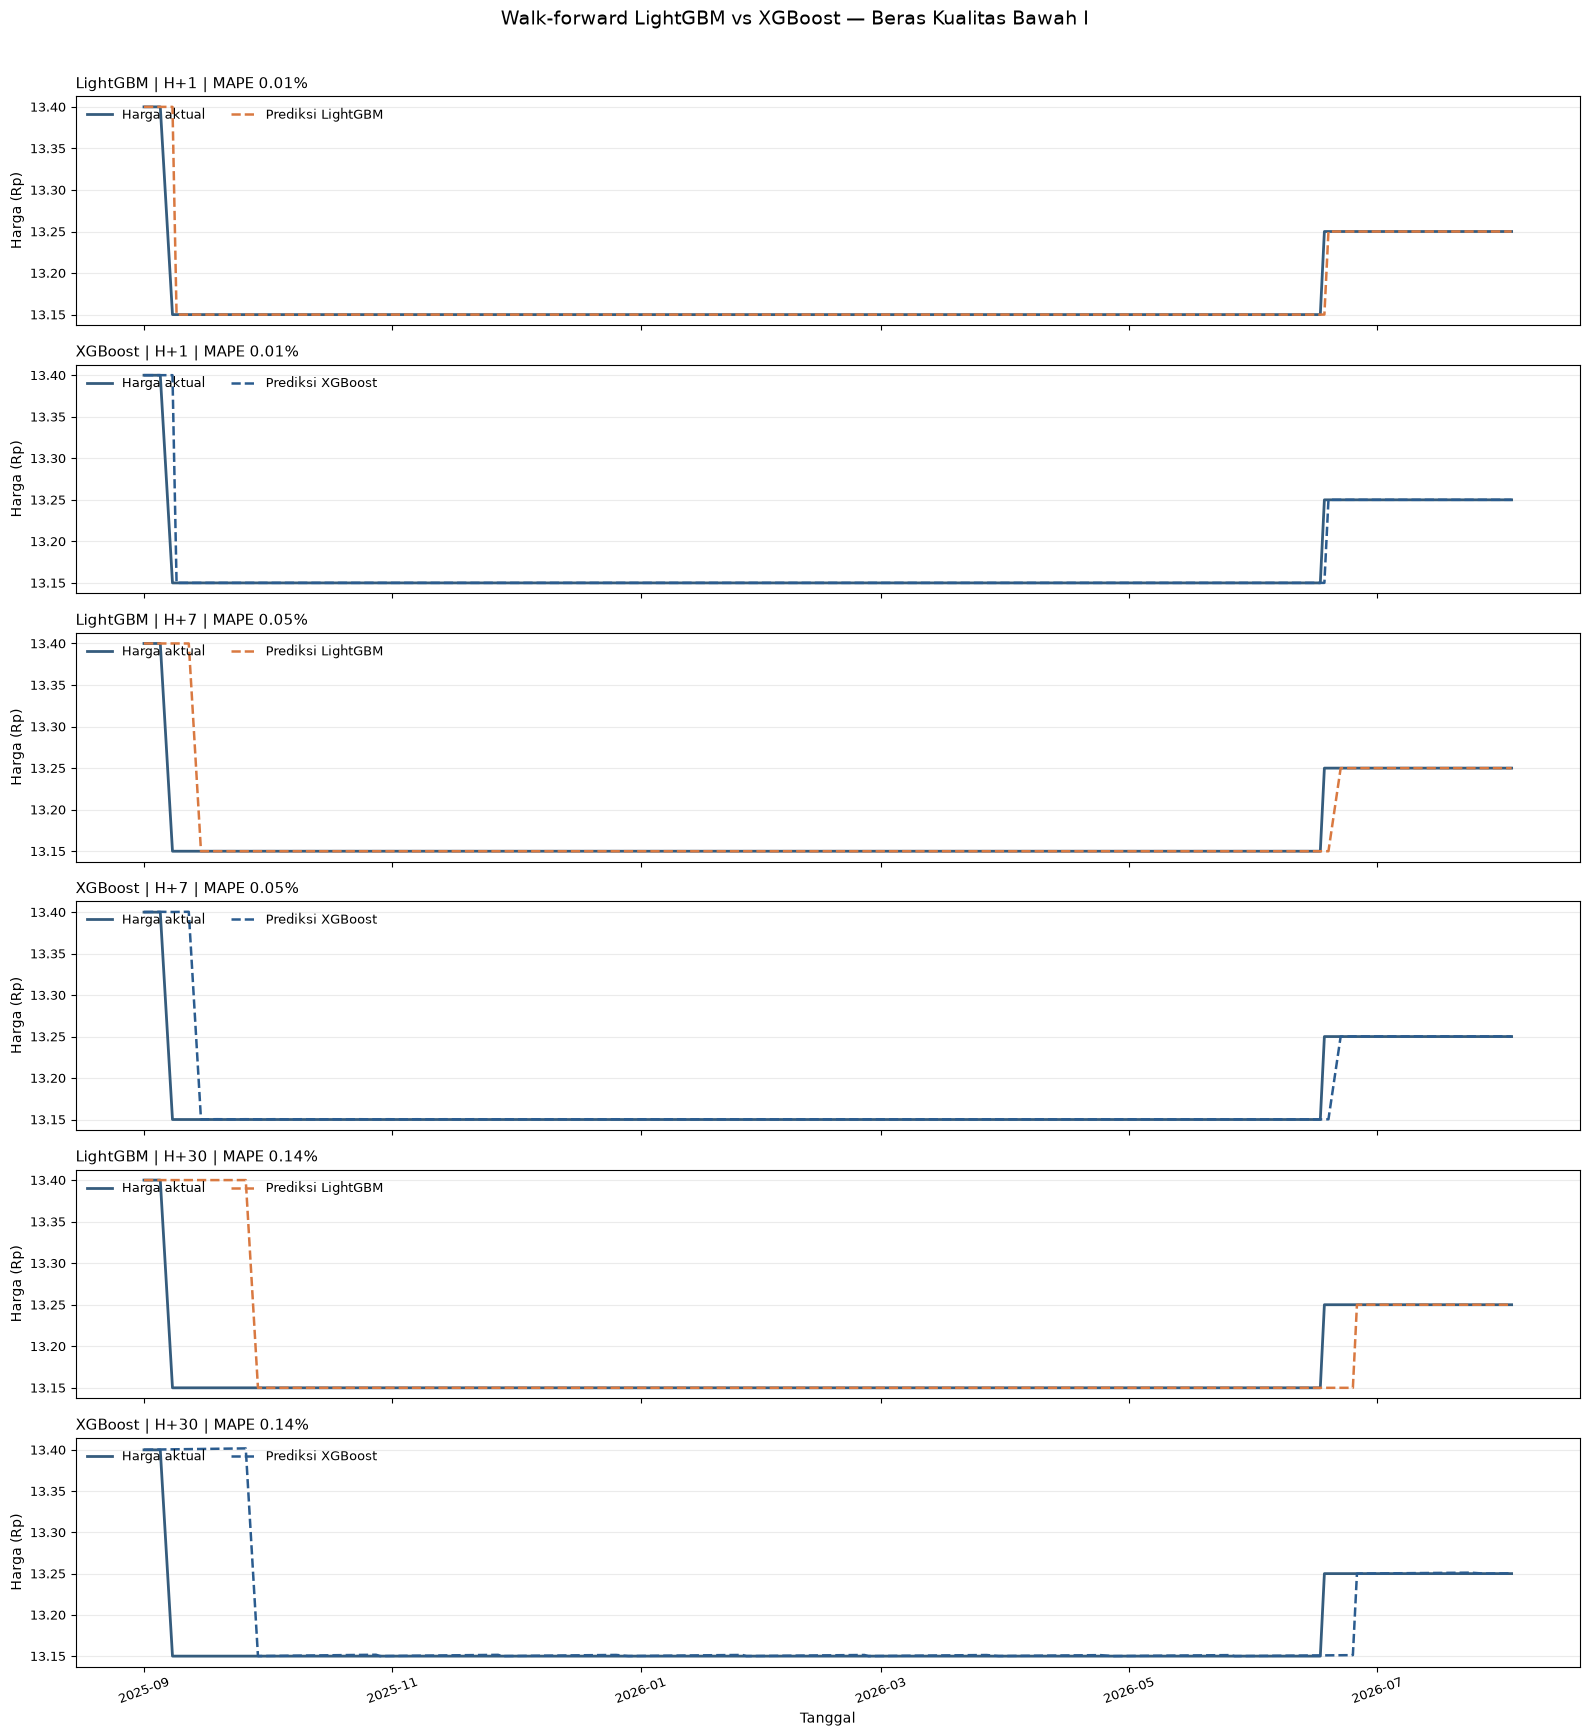

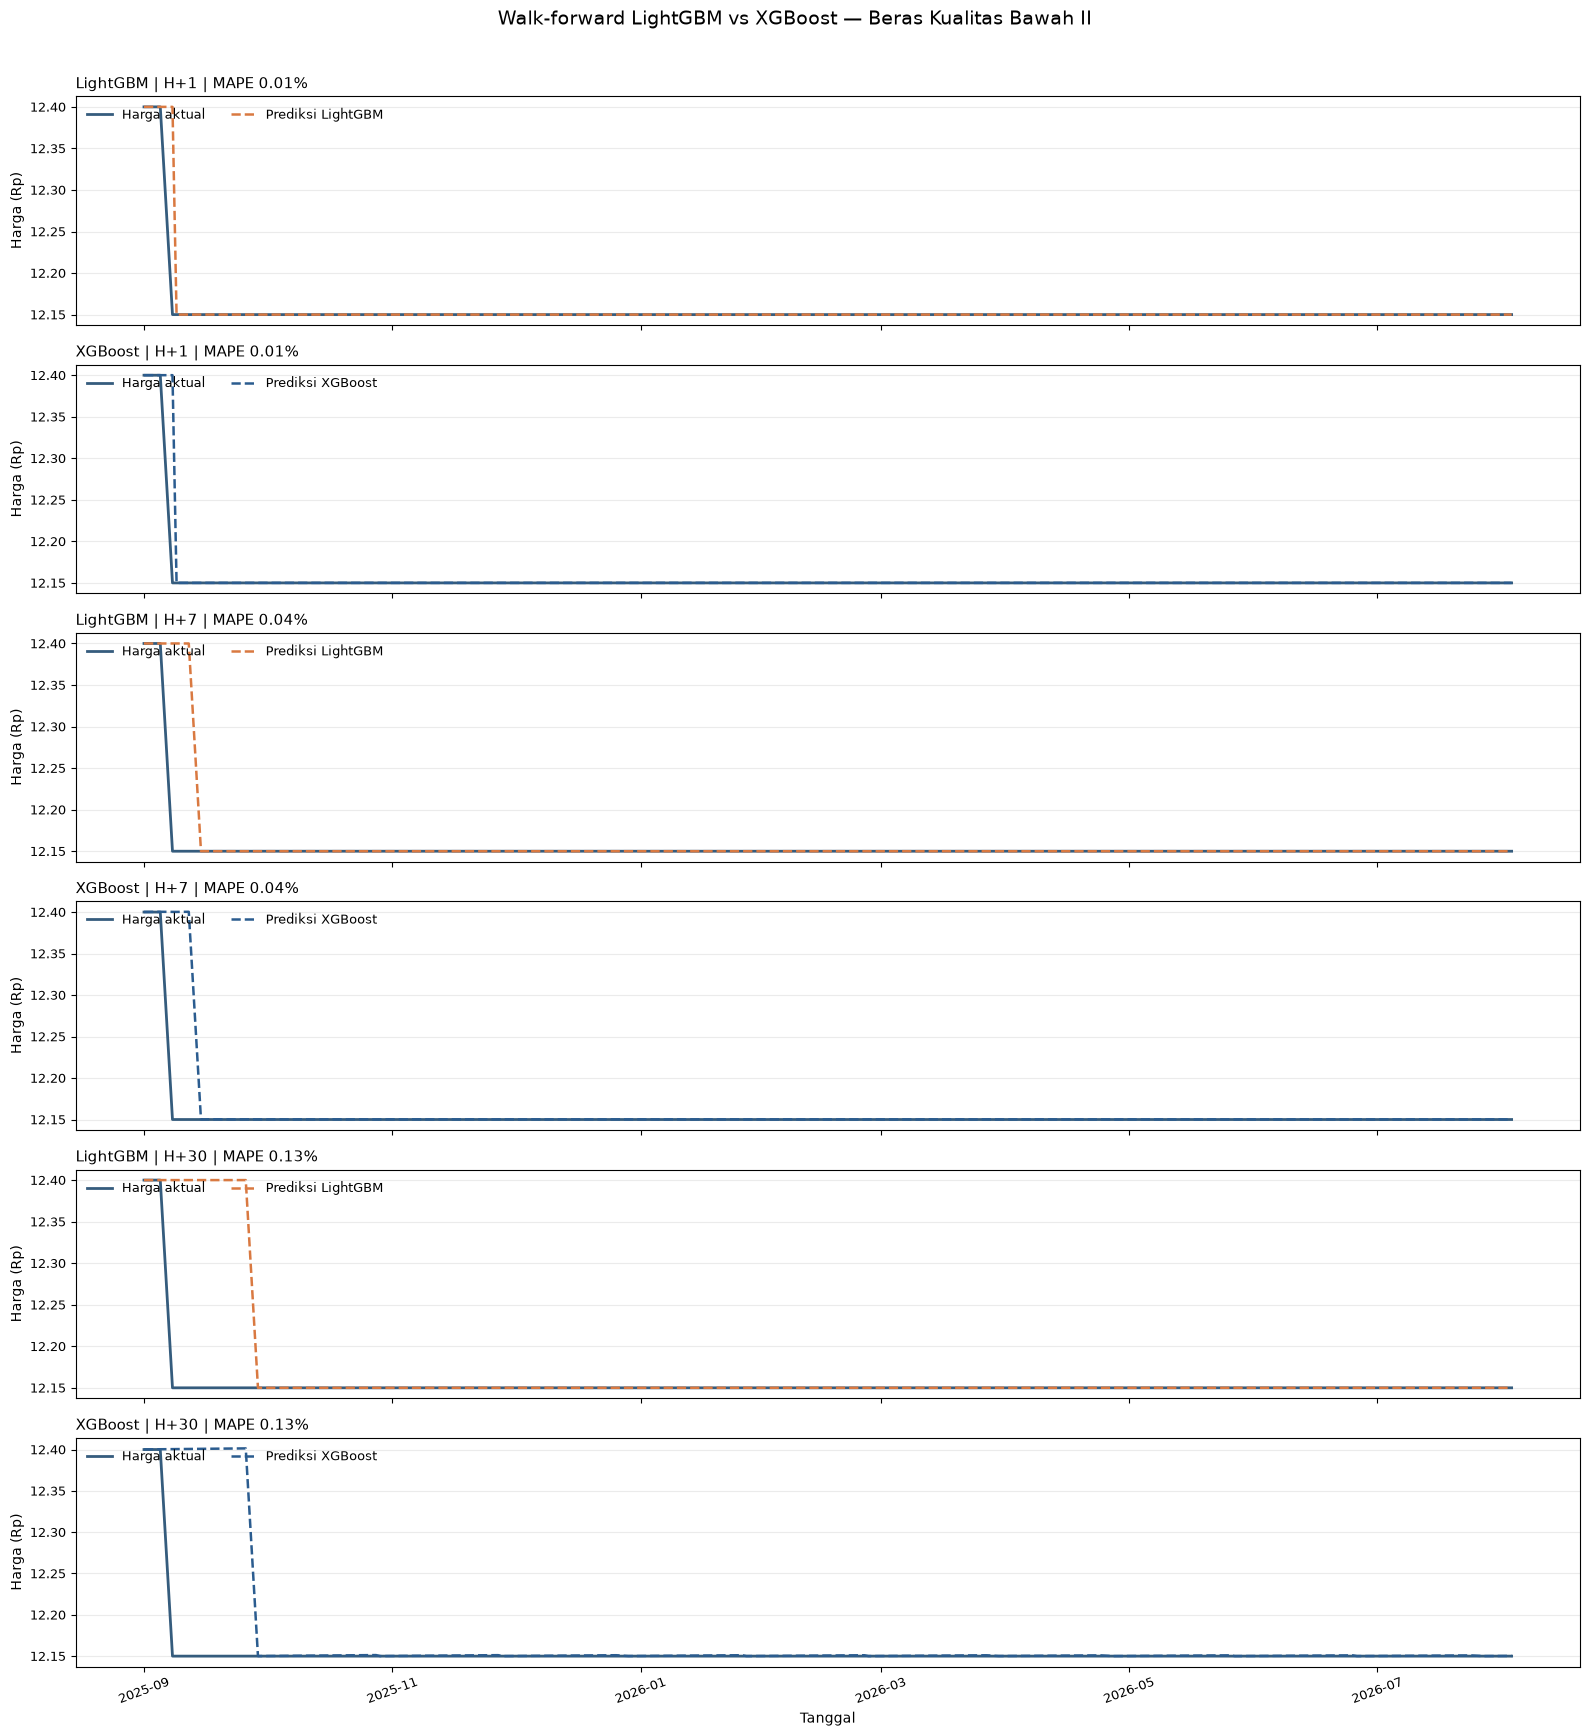

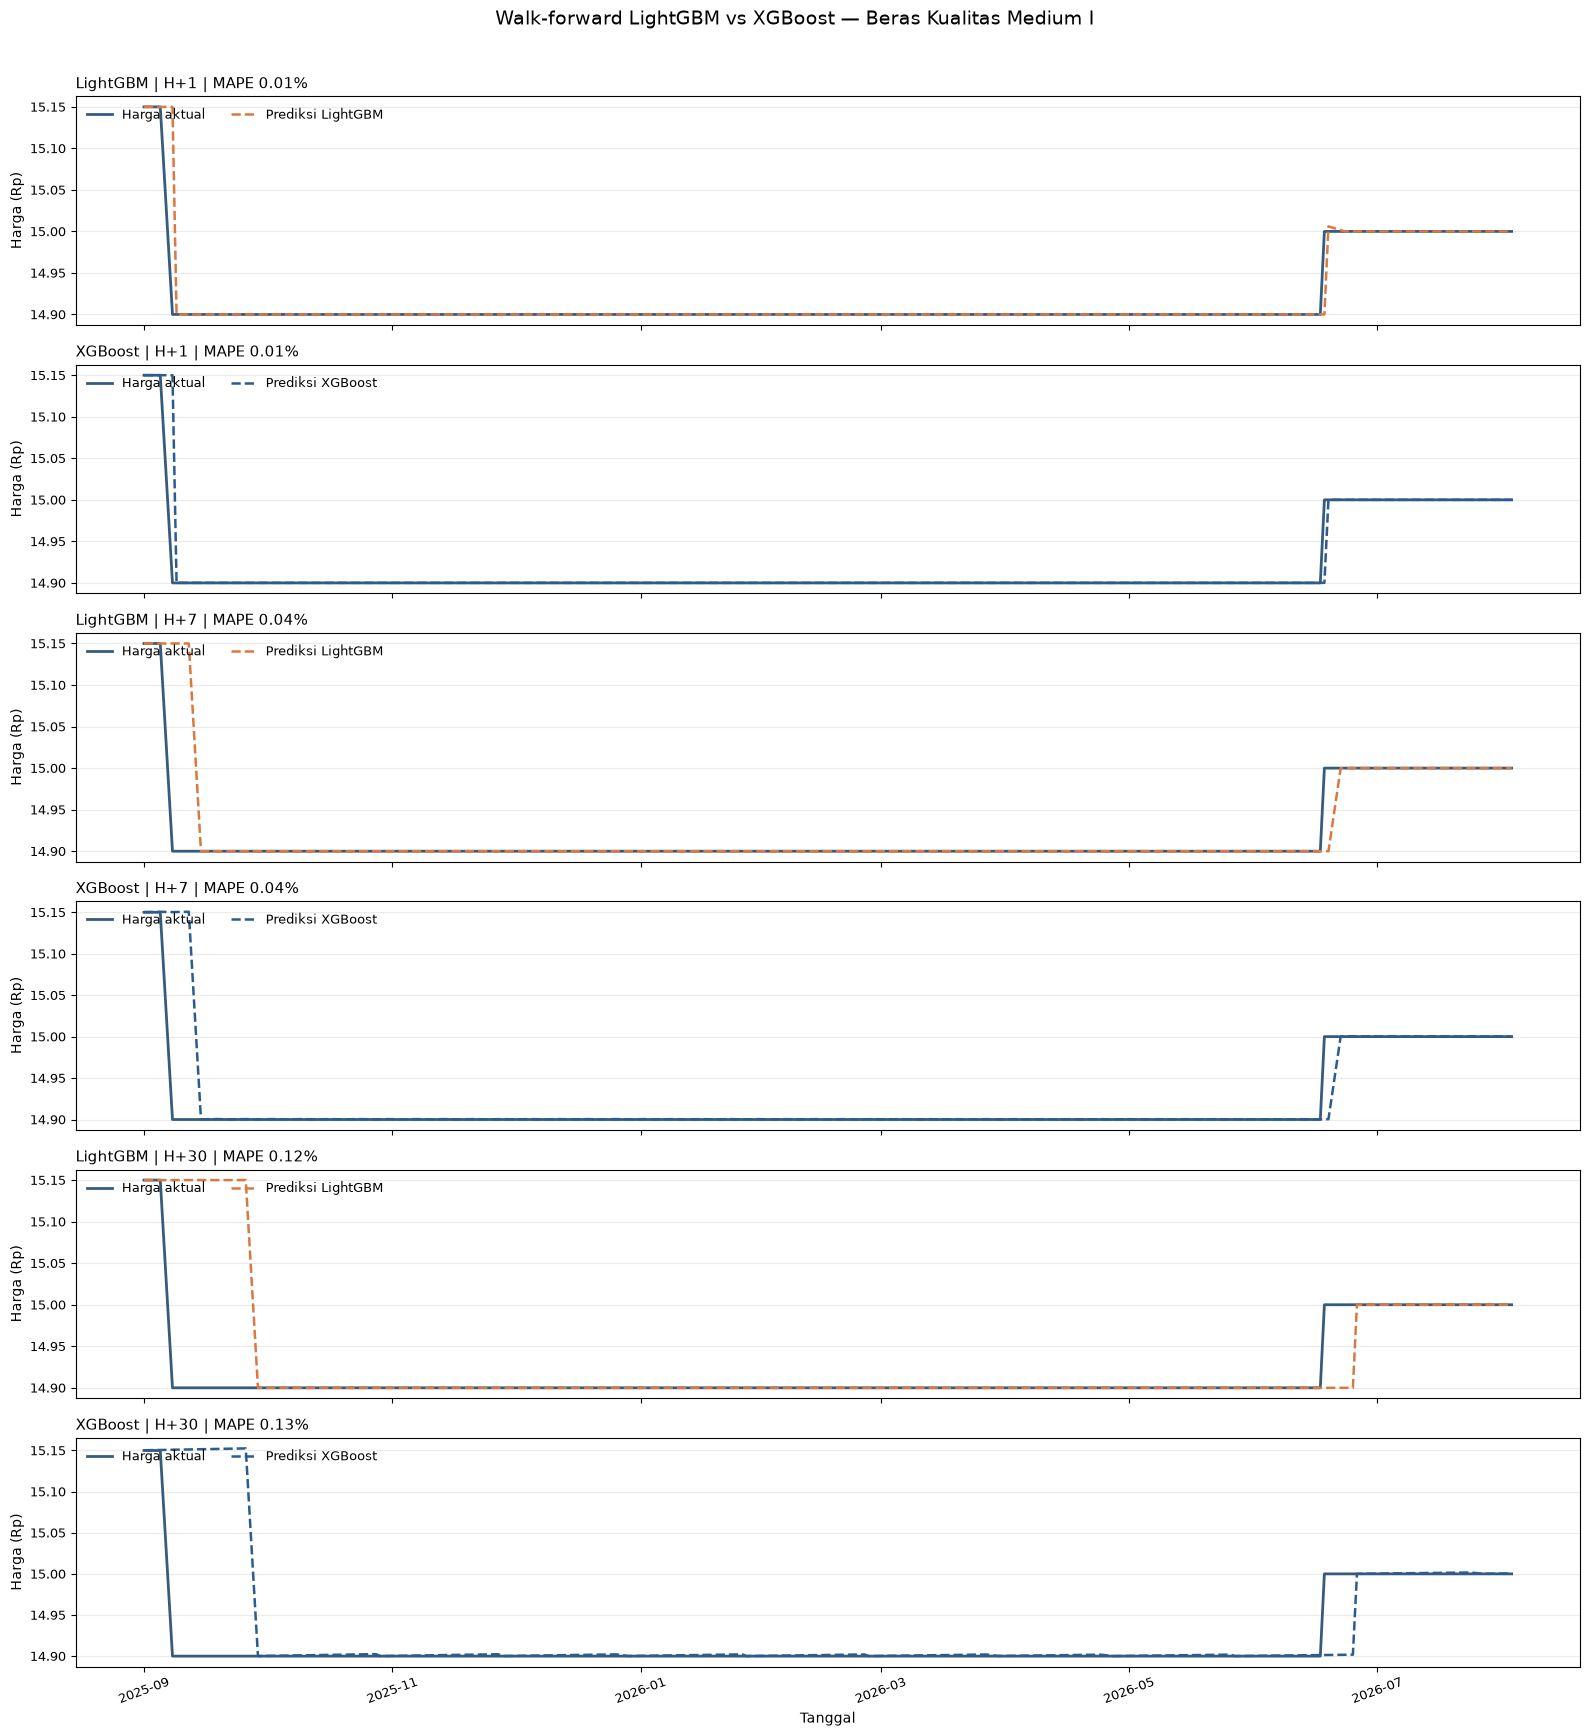

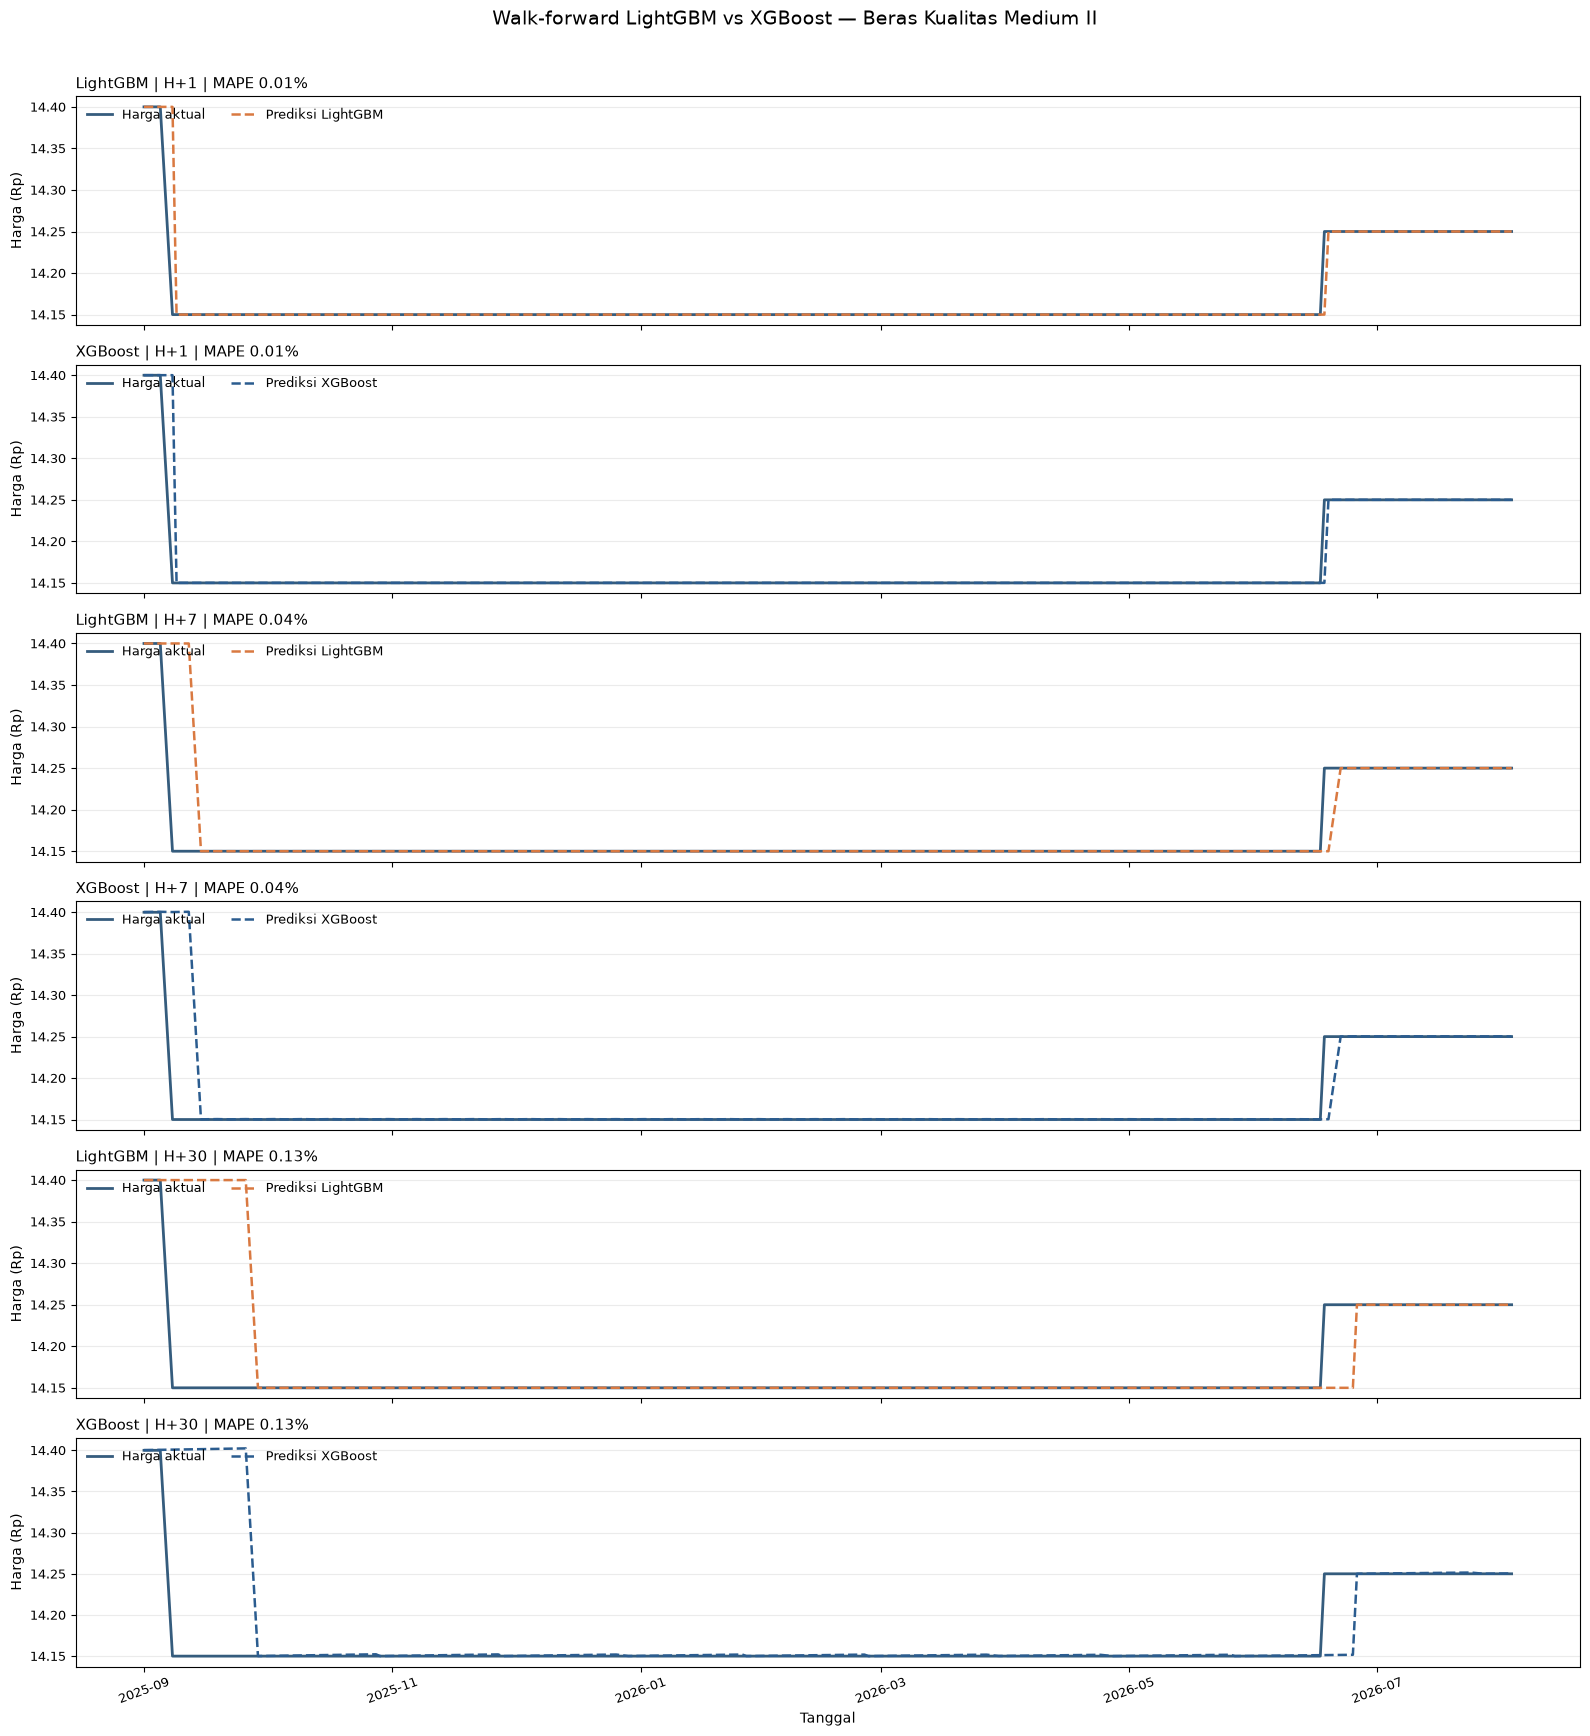

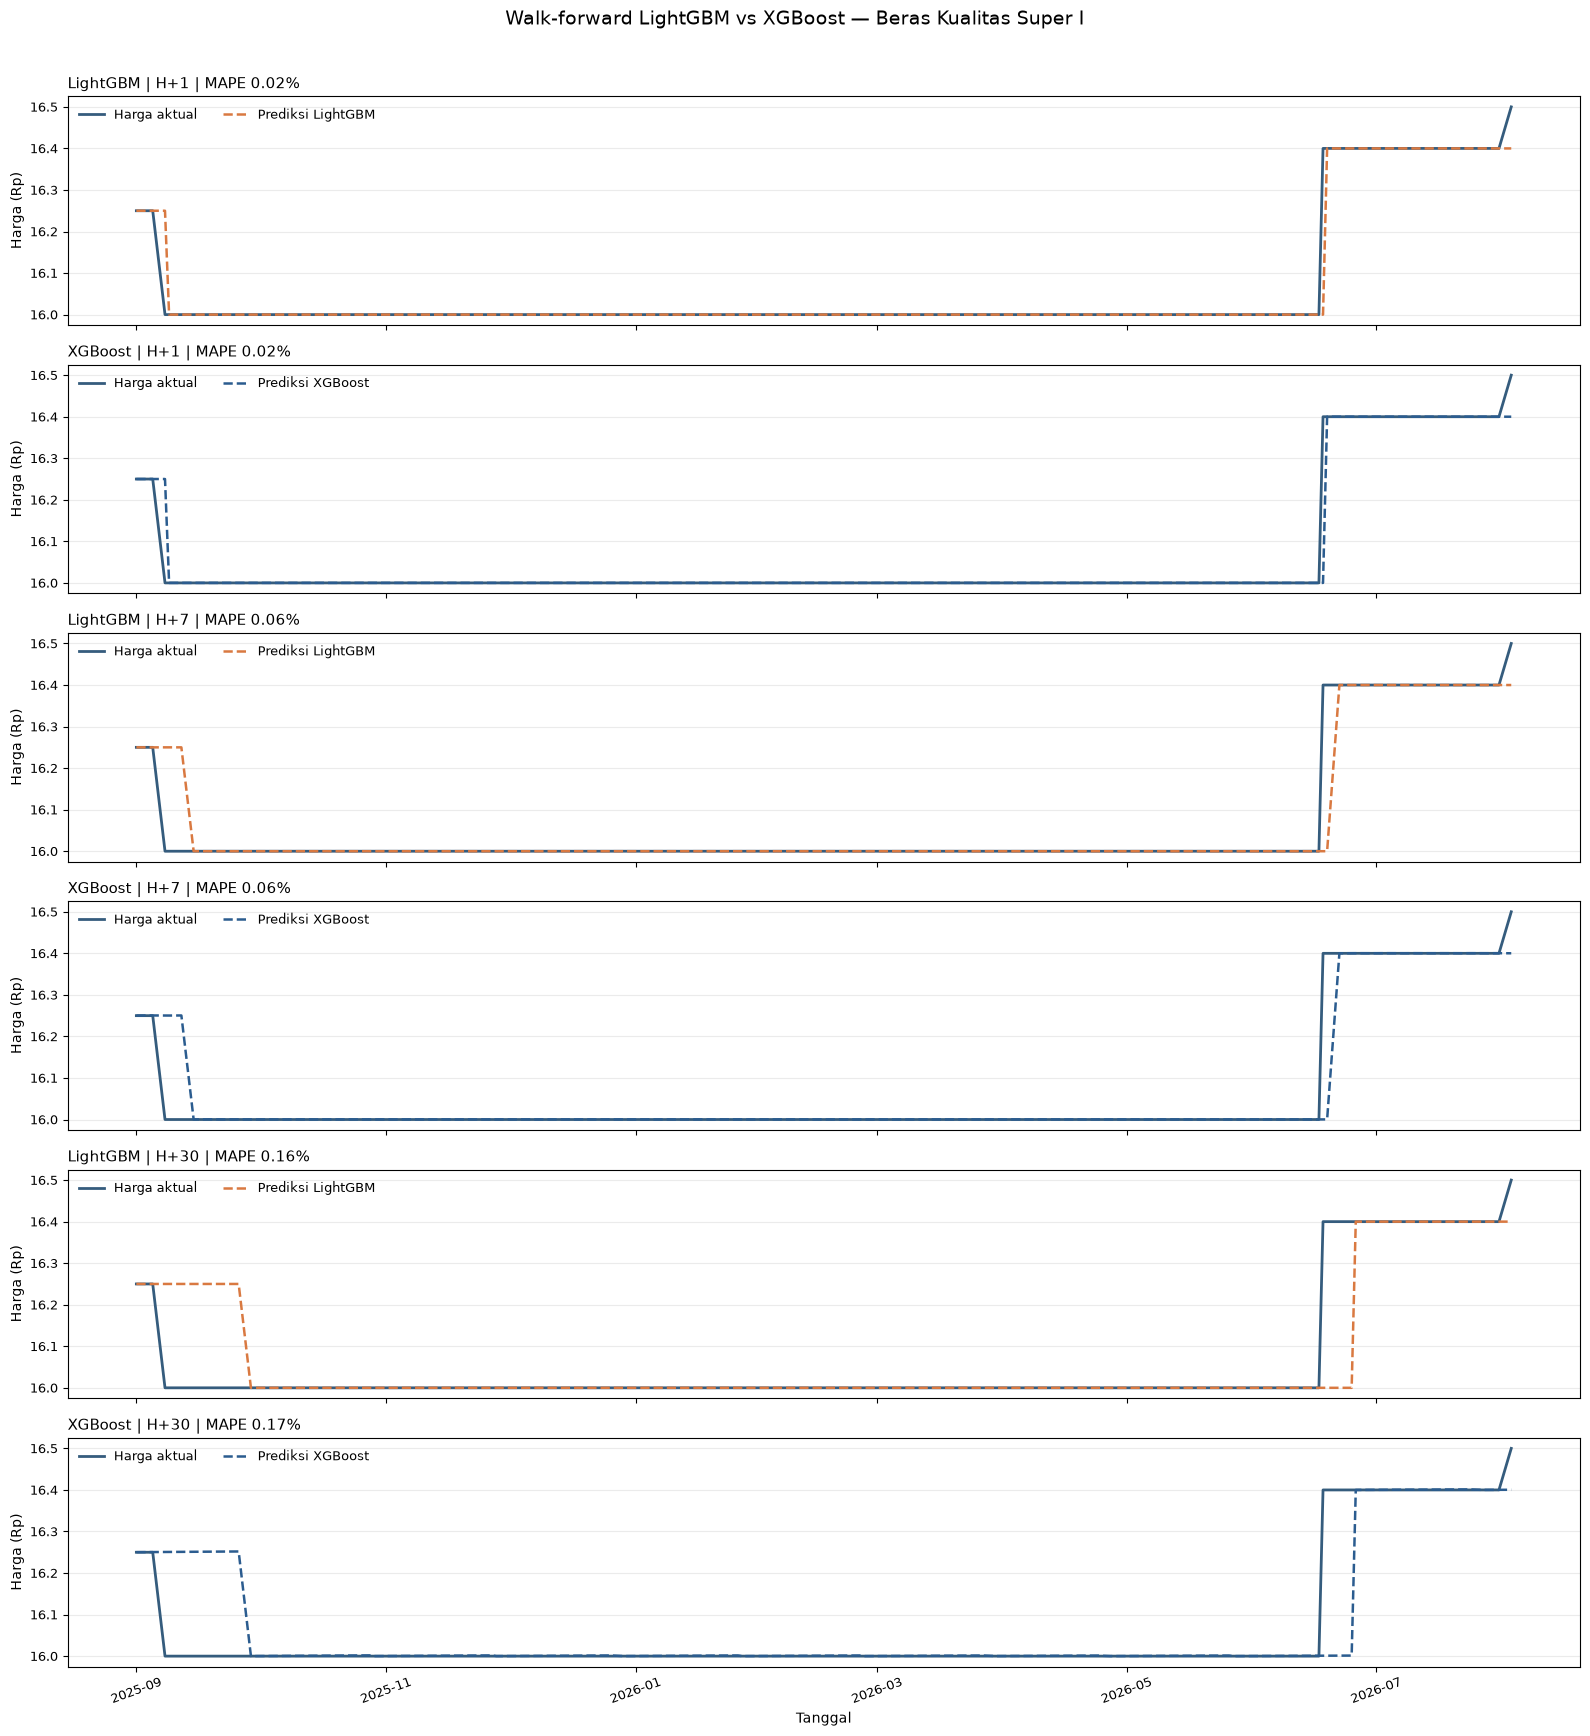

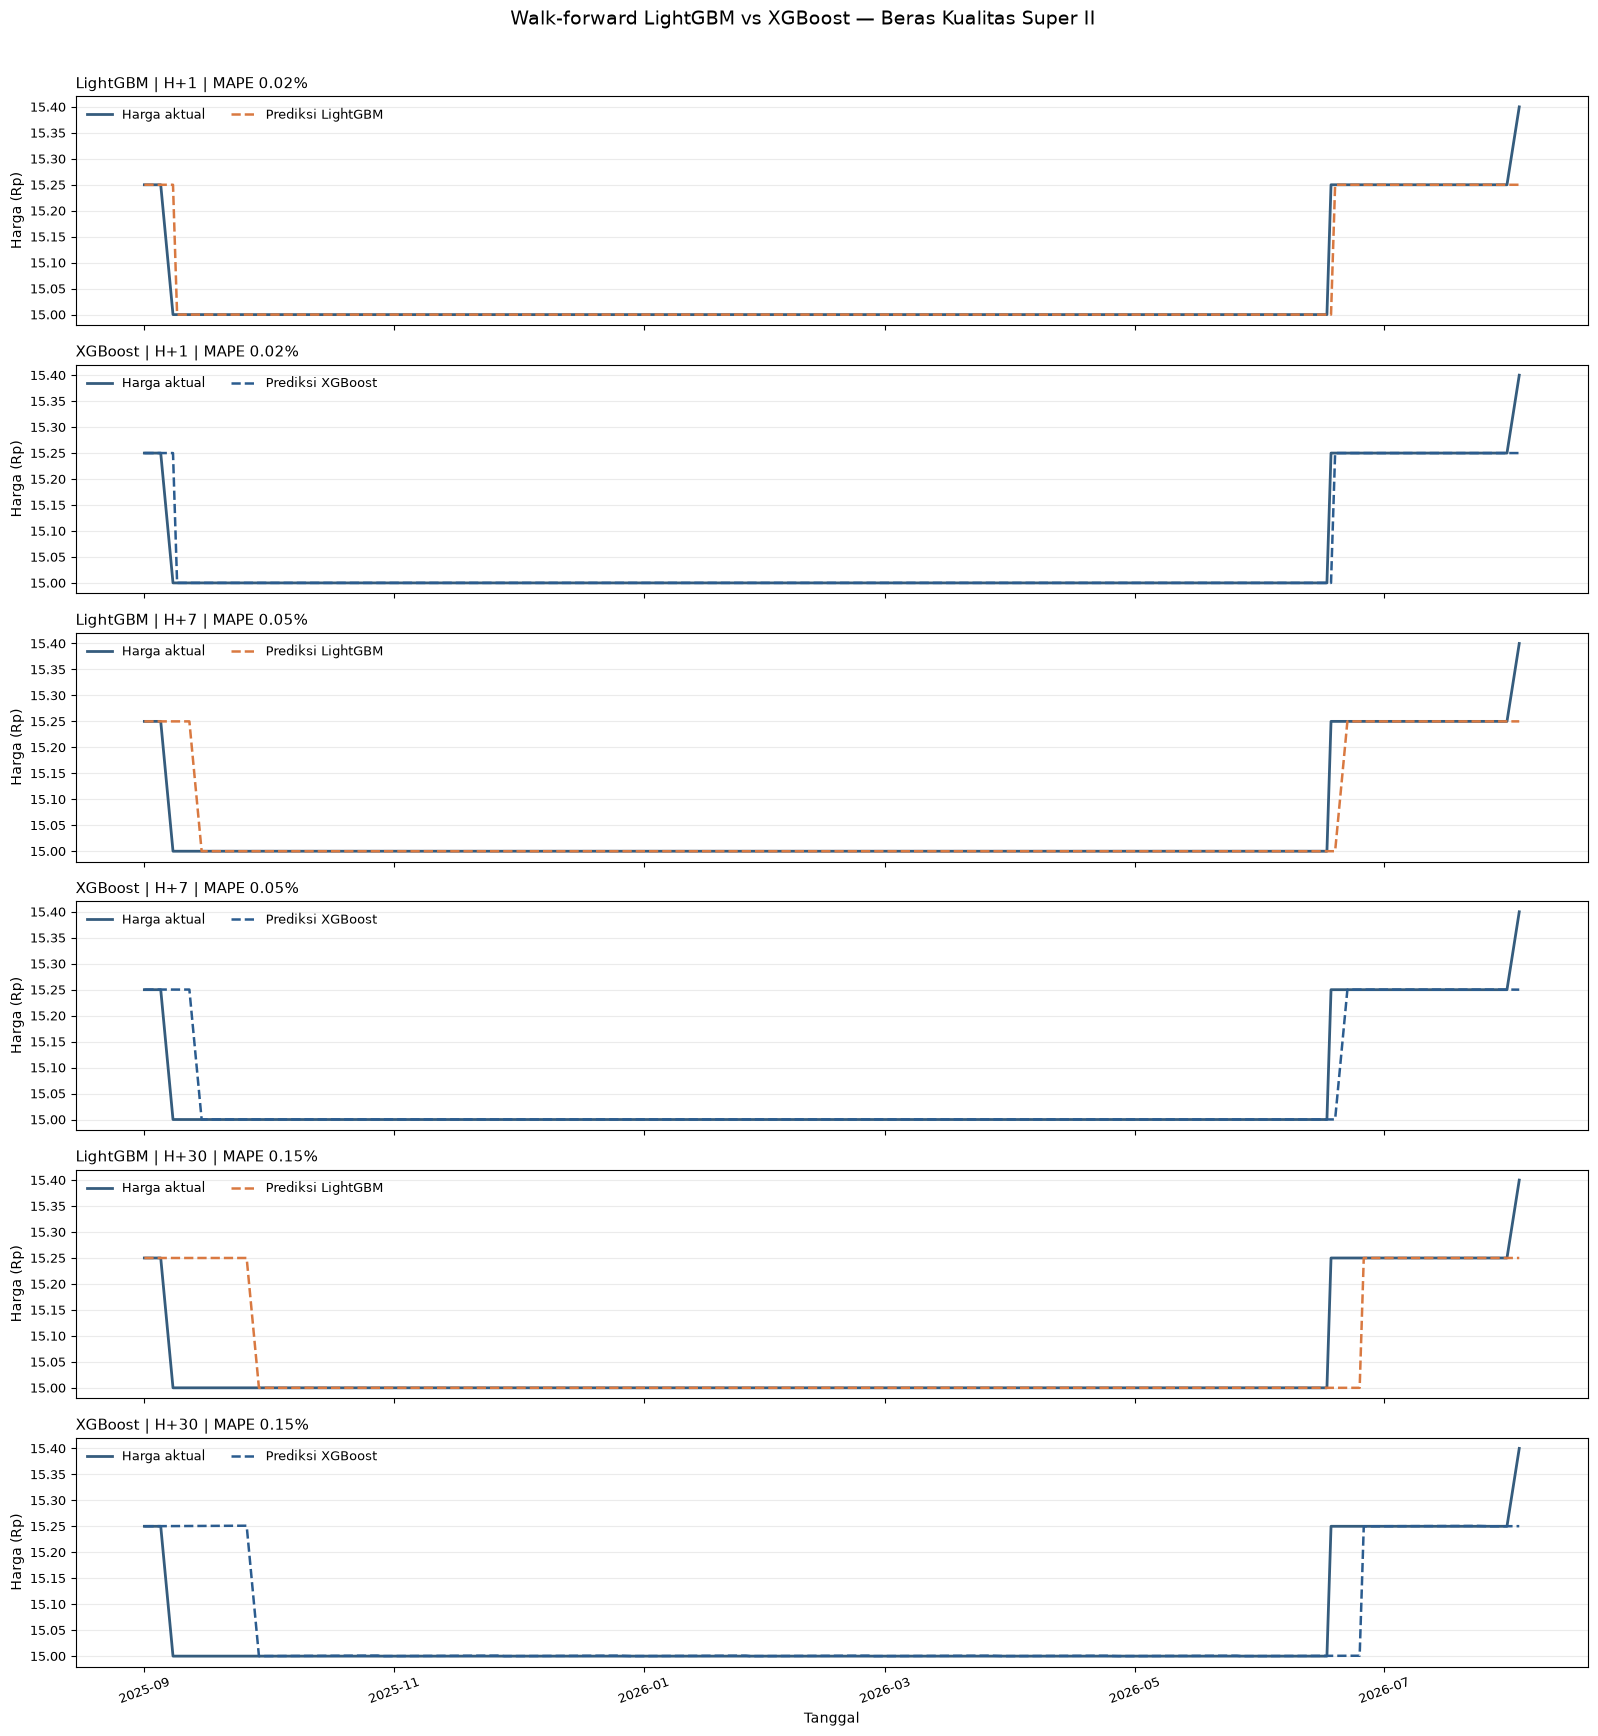

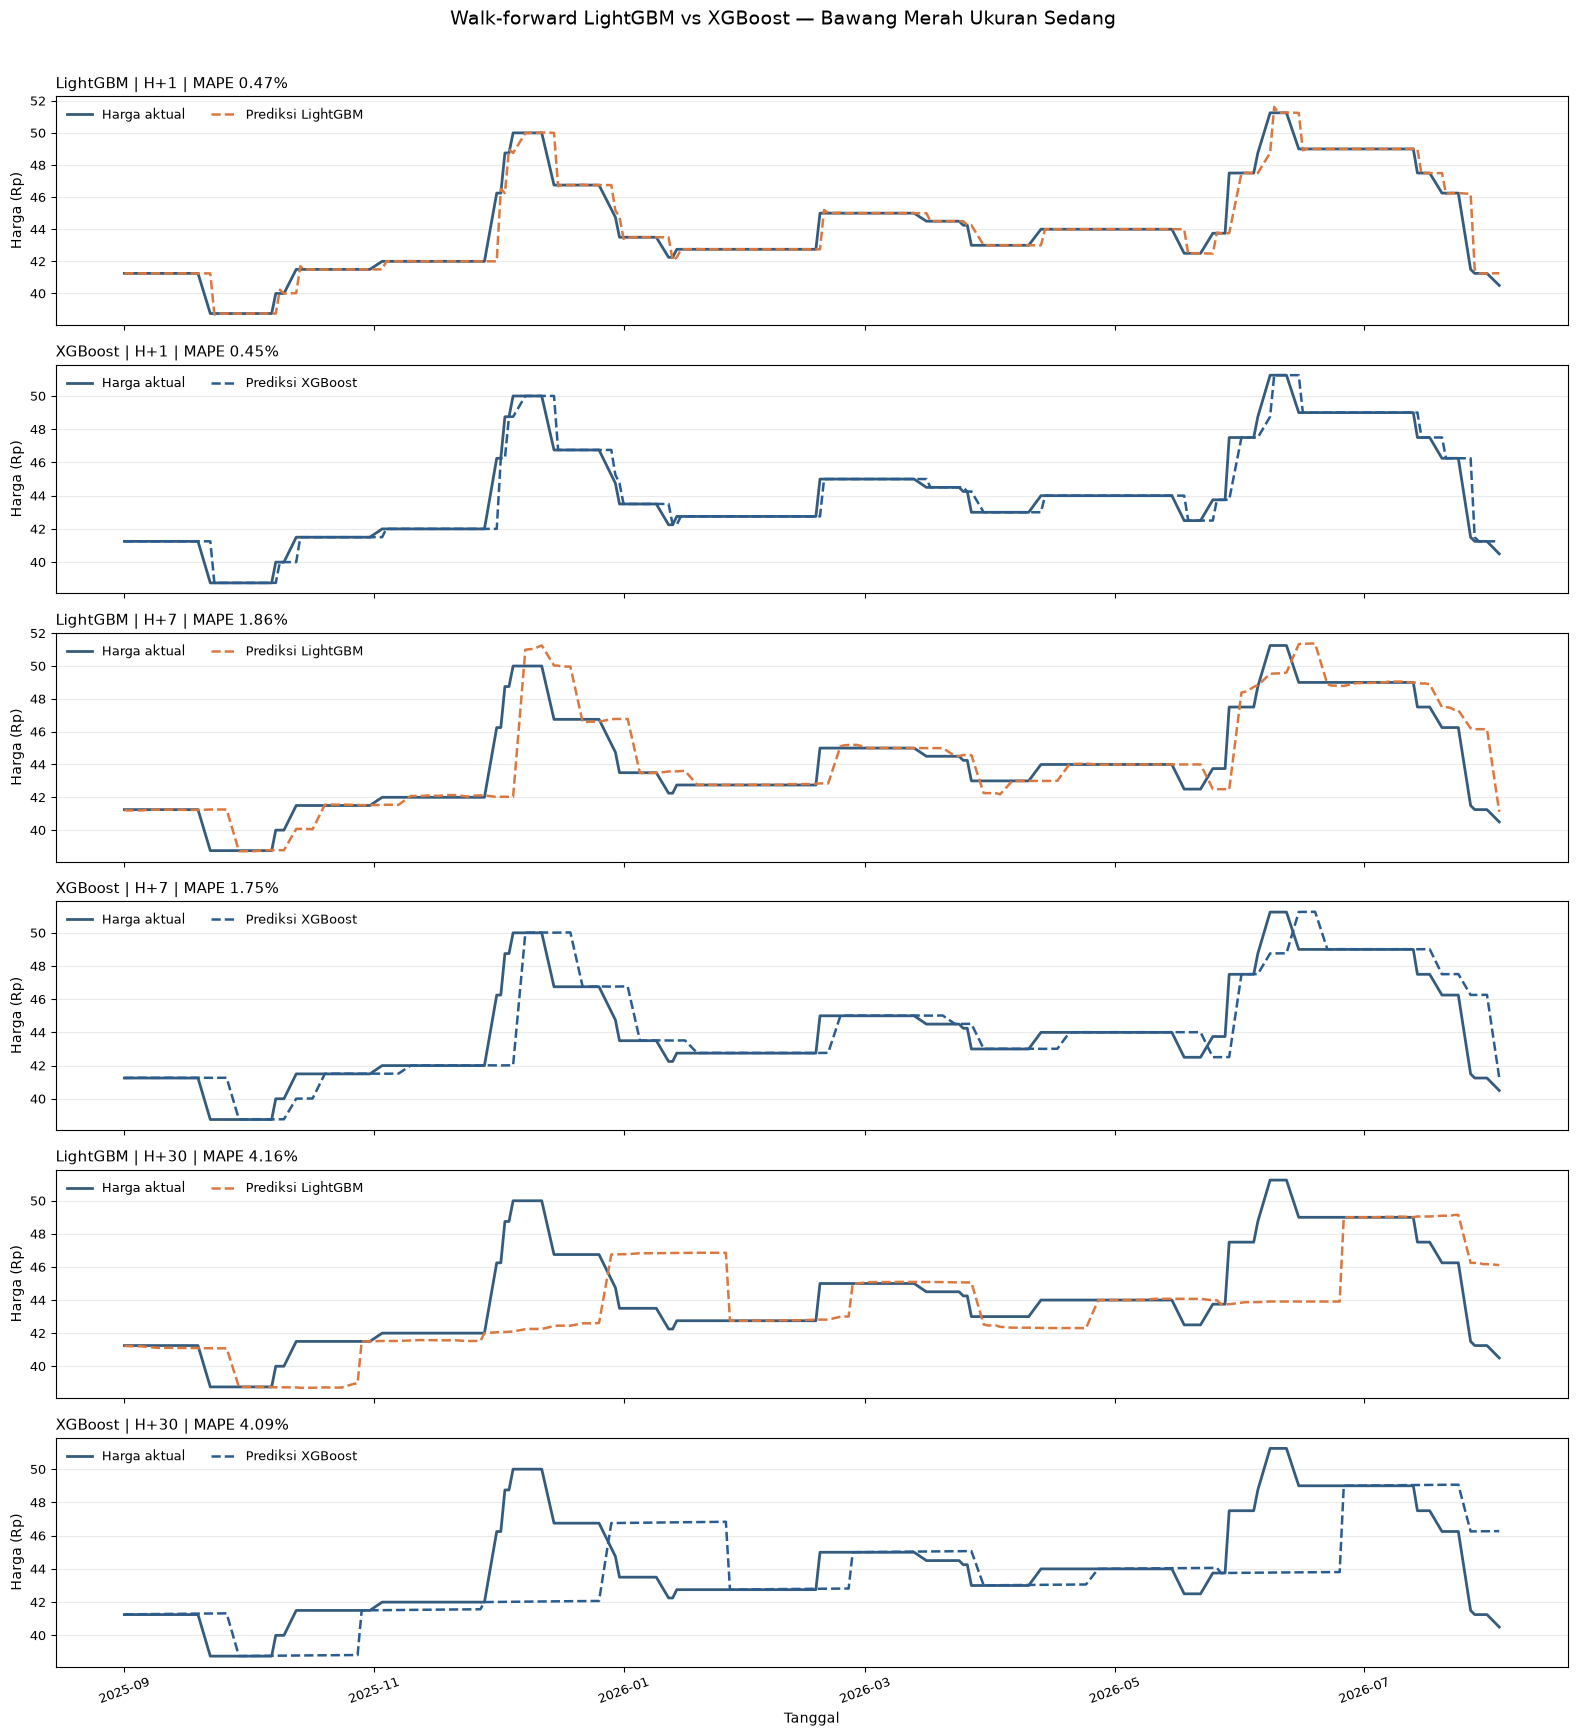

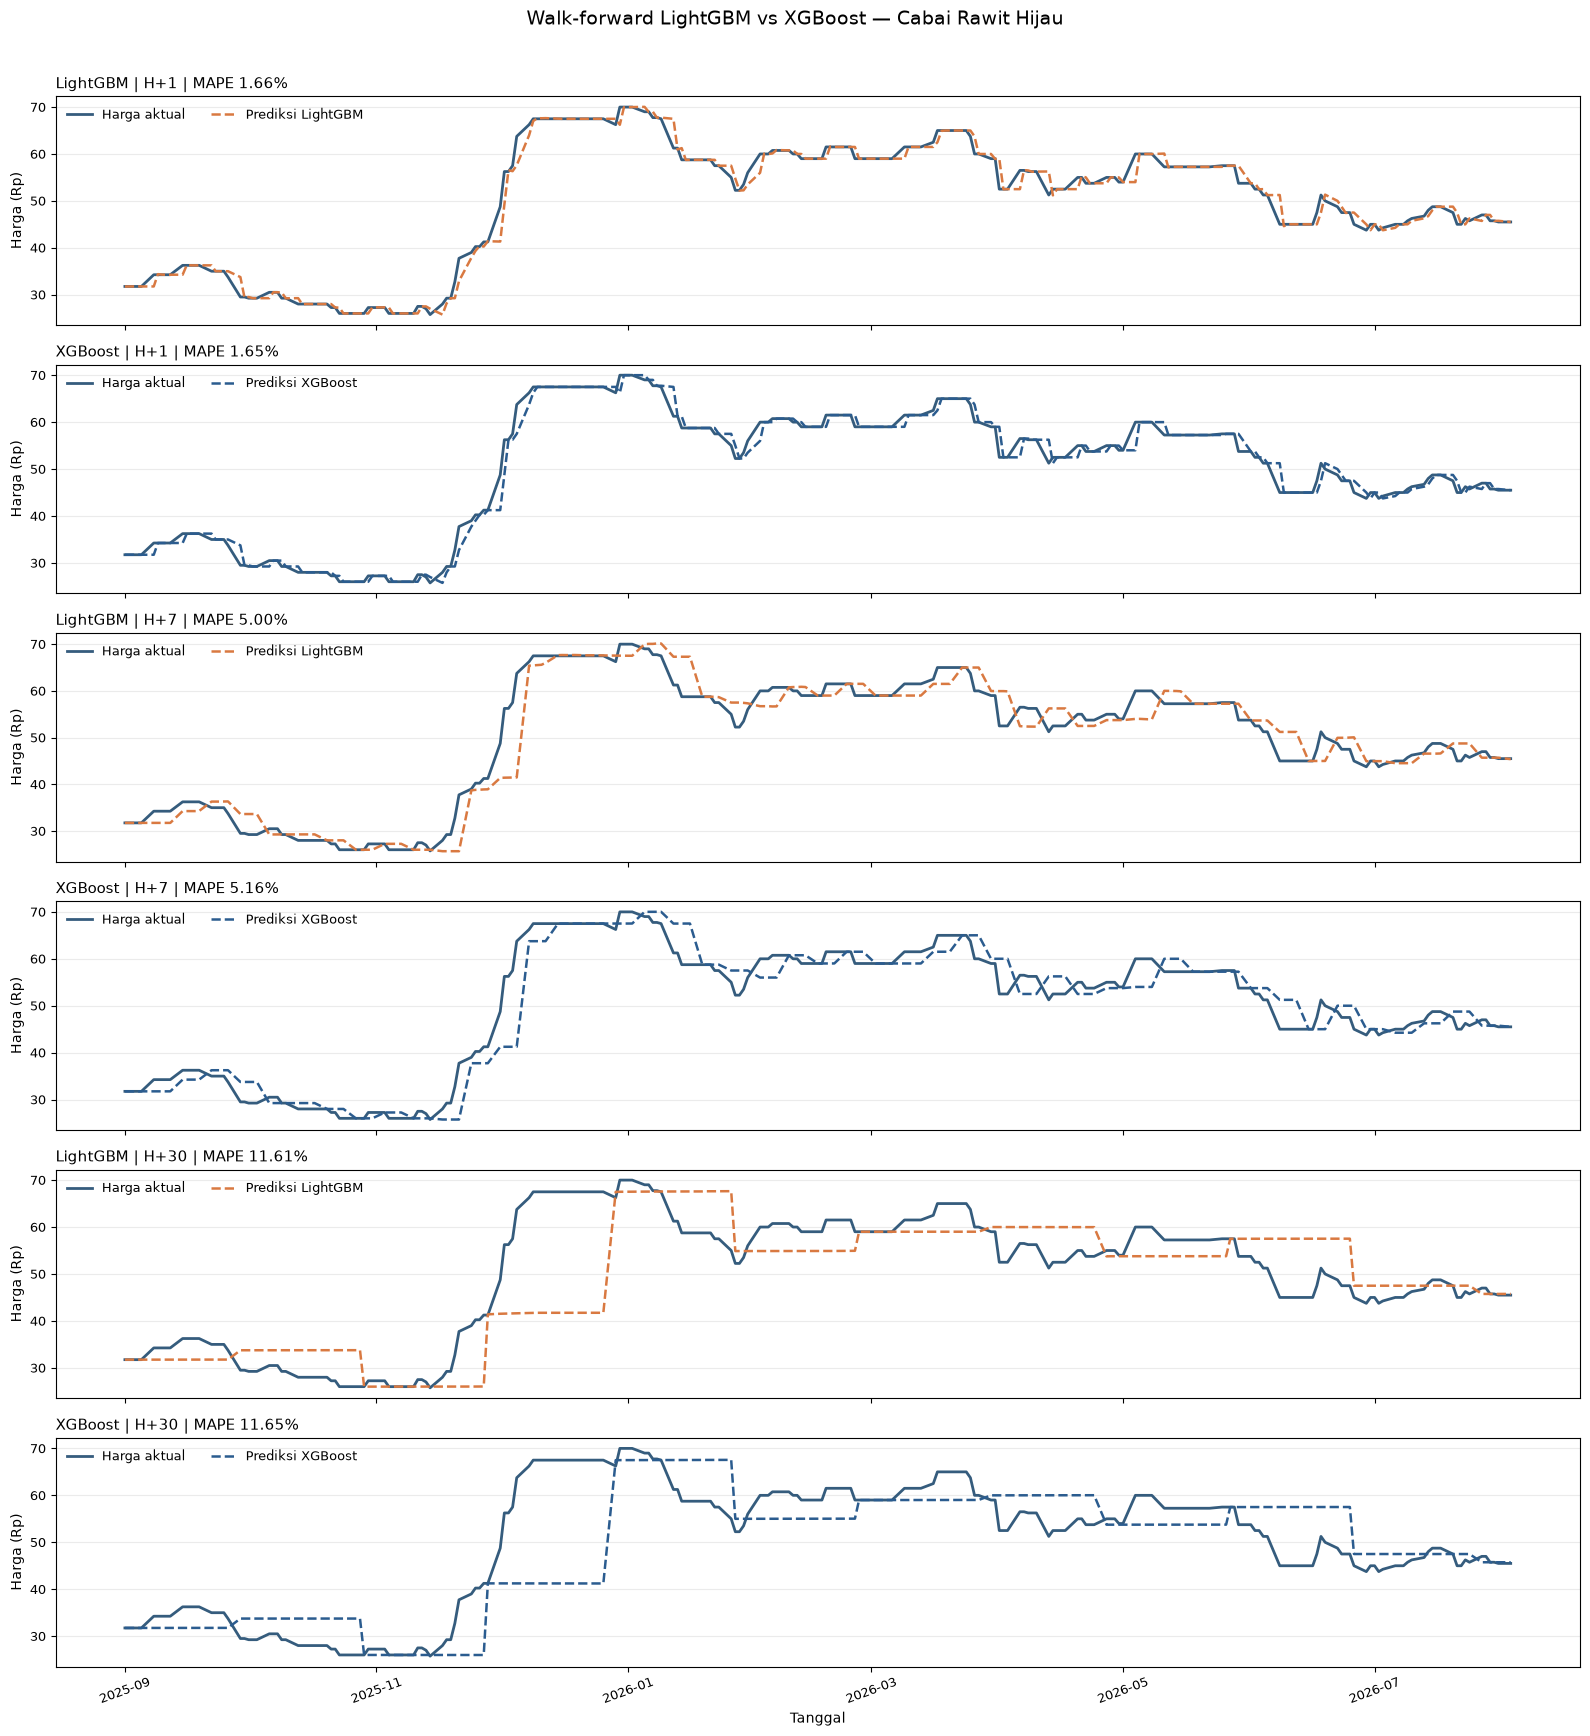

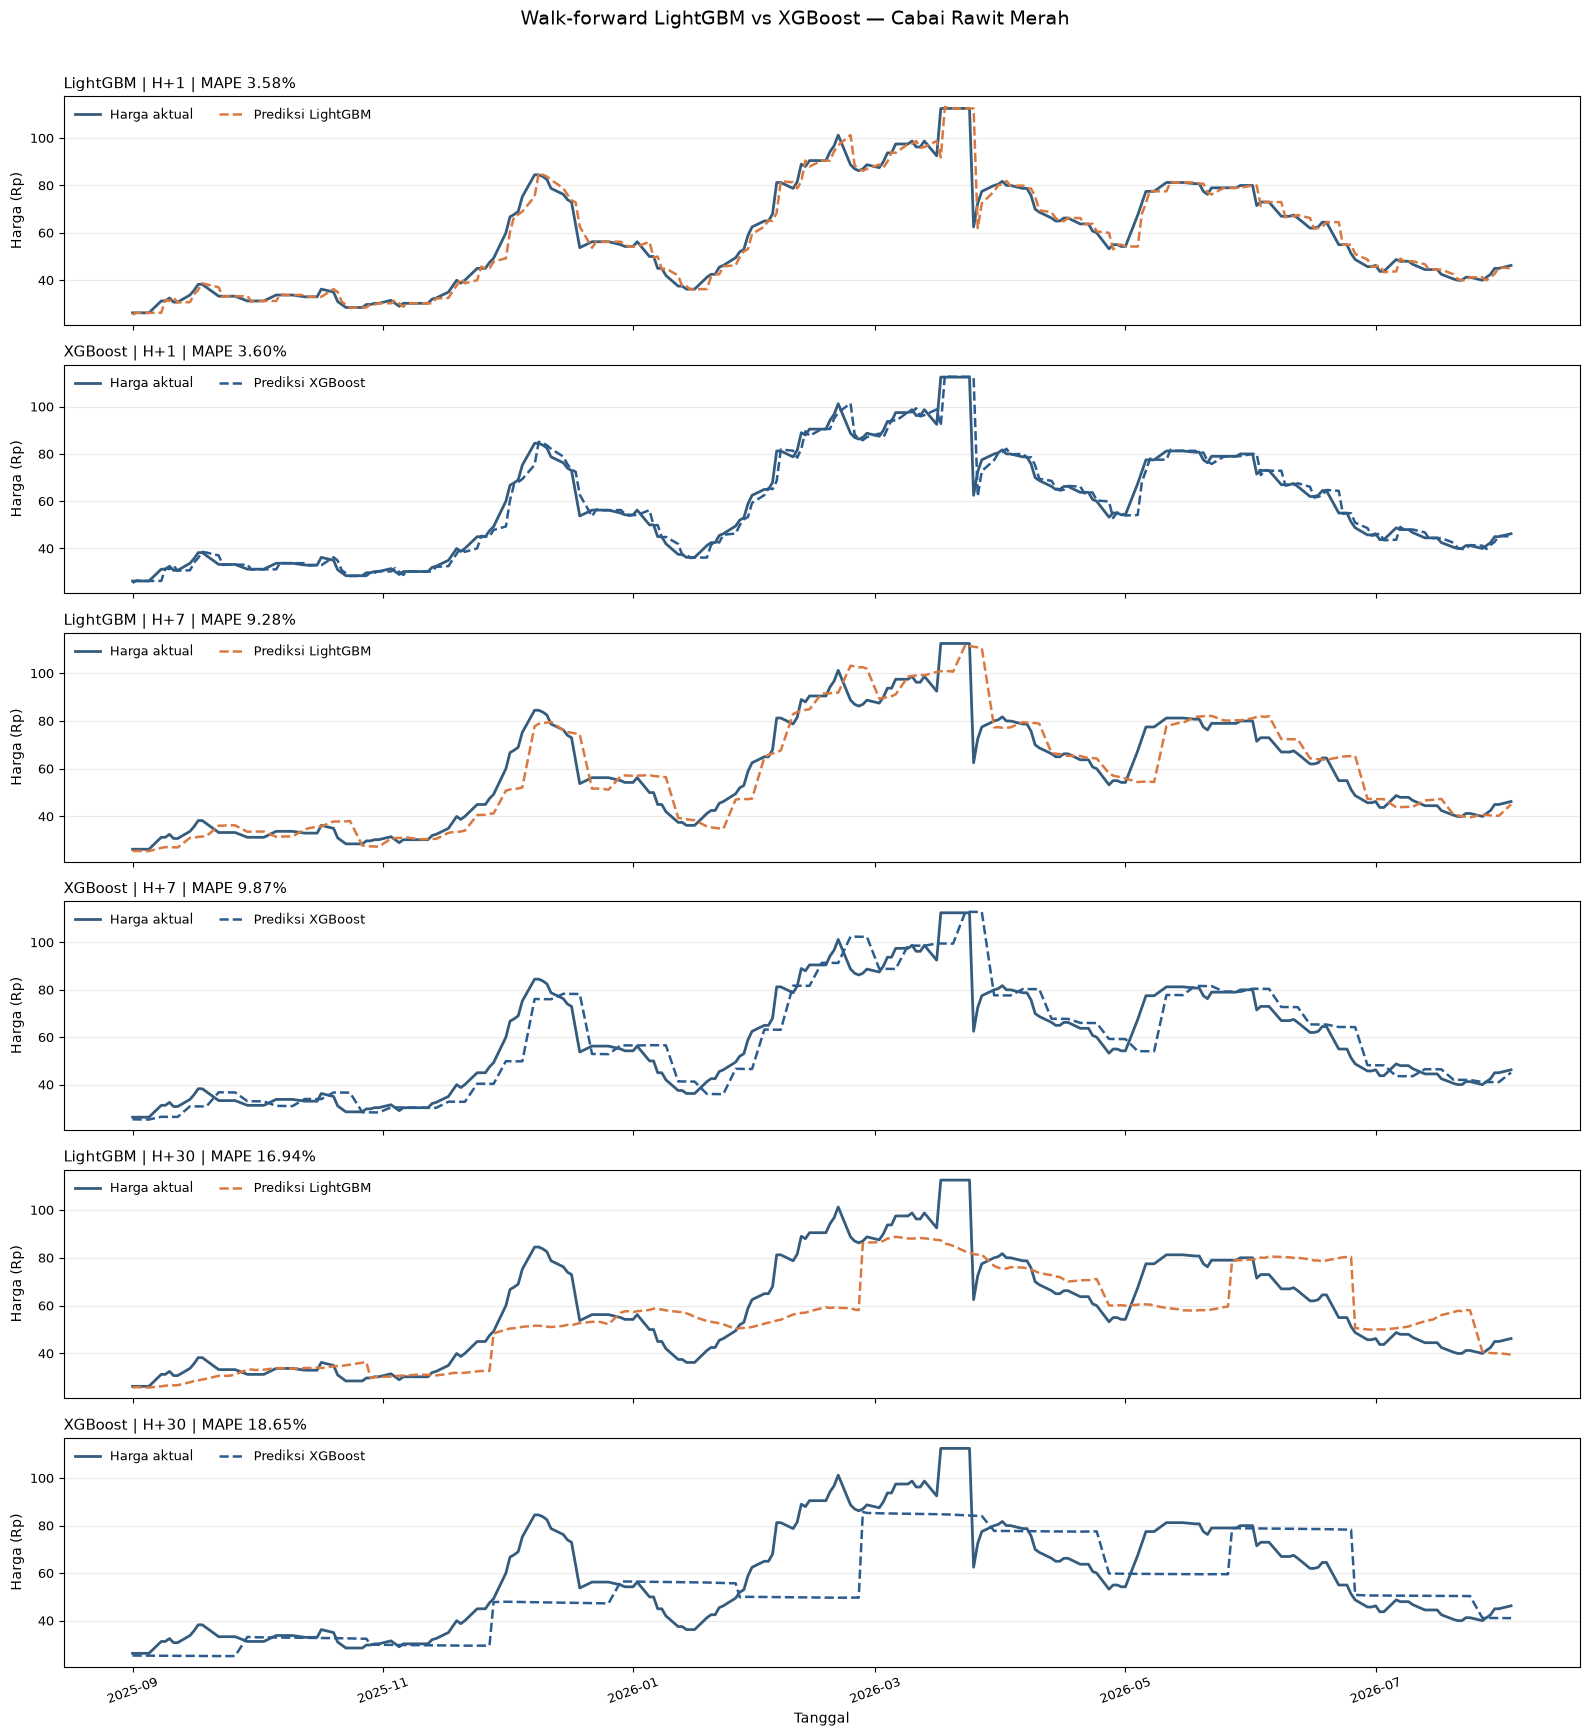

In [41]:
plot_walkforward(
    {
        "LightGBM": df_walkforward_predictions,
        "XGBoost": df_walkforward_predictions_xgb,
    },
    "Walk-forward LightGBM vs XGBoost",
)

## Menyimpan Final Model XGBoost


In [42]:
save_forecasters(forecasters_ga_xgb, "final_xgb", "final_xgb")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te